In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [6]:
units = pd.read_csv('units_L234.csv').copy()

In [7]:
def clean_dataset(units):

    mask_layer = ((units['layer'] == 'L2/3') | (units['layer'] == 'L4'))
    mask_area = (units['brain_area'] == 'V1')
    mask = mask_area & mask_layer

    data = units[mask].copy()
    data = data.drop(columns=['pvals_ori_fdr', 'pvals_dir_fdr', 'brain_area'])
    data['pt_root_id'] = data['pt_root_id'].astype(np.int64)

    for c in ['pt_position_x', 'pt_position_y', 'pt_position_z']:
        data[c] = data[c].astype(np.float32)

    return data

In [8]:
units_cleaned = clean_dataset(units)

In [9]:
mask_exc = (units_cleaned['classification_system'] == 'excitatory_neuron')
mask_inh = (units_cleaned['classification_system'] == 'inhibitory_neuron')

mask_l23 = (units_cleaned['layer'] == 'L2/3')
mask_l4 = (units_cleaned['layer'] == 'L4')

In [10]:
E_L23 = units_cleaned[mask_exc & mask_l23].copy().reset_index(drop=True)
I_L23 = units_cleaned[mask_inh & mask_l23].copy().reset_index(drop=True)
E_L4 = units_cleaned[mask_exc & mask_l4].copy().reset_index(drop=True)
I_L4 = units_cleaned[mask_inh & mask_l4].copy().reset_index(drop=True)

In [11]:
pathways = [
    # post = E_L23

    ('E23_E23', E_L23, E_L23),
    ('I23_E23', I_L23, E_L23),
    ('E4_E23', E_L4, E_L23),
    ('I4_E23', I_L4, E_L23),

    # post = I_L23s

    ('E23_I23', E_L23, I_L23),
    ('I23_I23', I_L23, I_L23),
    ('E4_I23', E_L4, I_L23),
    ('I4_I23', I_L4, I_L23),
]


path_syn = 'synapses_L234.csv'
synapses = pd.read_csv(f'{path_syn}').copy()
mean_syn_size = synapses['size'].mean()
synapses['size'] /= mean_syn_size

In [12]:
def circular_diff_ori(a: np.ndarray, b: np.ndarray) -> np.ndarray:
    diff = (a - b + np.pi / 2) % np.pi - np.pi / 2
    return diff.astype(np.float32)

In [13]:
def polar_distance(theta1,theta2):
    return np.sqrt((np.cos(2*theta1)-np.cos(2*theta2))**2+ (np.sin(2*theta1)-np.sin(2*theta2))**2)

In [14]:
def existing_connections_v1(pre_pop, post_pop, syn, metric=["Euclidean"]):

    pre_feat = [
        "pt_root_id",
        "pt_position_x",
        "pt_position_z",
        "strategy_axon",
    ]

    post_feat = [
        "pt_root_id",
        "pt_position_x",
        "pt_position_z",
        "strategy_dendrite",
    ]

    if "Ori_Diff" in metric:
        pre_pop = pre_pop[pre_pop["selective_ori"] == "True"].copy().reset_index(drop=True)
        post_pop = post_pop[post_pop["selective_ori"] == "True"].copy().reset_index(drop=True)

        pre_feat.append("pref_ori_fit")
        post_feat.append("pref_ori_fit")

    if "Euclidean" in metric:
        pre_feat.append("pt_position_y")
        post_feat.append("pt_position_y")

    pre_pop = pre_pop[pre_feat].copy().rename(columns=lambda x: f"pre_{x}")
    post_pop = post_pop[post_feat].copy().rename(columns=lambda x: f"post_{x}")

    syn = syn[
        syn["pre_pt_root_id"].isin(pre_pop["pre_pt_root_id"])
        & syn["post_pt_root_id"].isin(post_pop["post_pt_root_id"])
    ].copy().reset_index(drop=True)

    conn = syn.merge(pre_pop, on="pre_pt_root_id").merge(post_pop, on="post_pt_root_id")

    conn = conn[
        conn["pre_pt_root_id"] != conn["post_pt_root_id"]
    ].reset_index(drop=True)

    dx = conn["pre_pt_position_x"].to_numpy() - conn["post_pt_position_x"].to_numpy()
    dz = conn["pre_pt_position_z"].to_numpy() - conn["post_pt_position_z"].to_numpy()

    conn = conn.drop(columns=[
        "pre_pt_position_x", "pre_pt_position_z",
        "post_pt_position_x", "post_pt_position_z",
    ])

    if "Euclidean" in metric:
        dy = conn["pre_pt_position_y"].to_numpy() - conn["post_pt_position_y"].to_numpy()
        conn = conn.drop(columns=["pre_pt_position_y", "post_pt_position_y"])
        conn["euclidean"] = np.sqrt(dx**2 + dy**2 + dz**2)
    else:
        conn["lateral"] = np.sqrt(dx**2 + dz**2)

    if "Ori_Diff" in metric:
        ori_pre = conn["pre_pref_ori_fit"].to_numpy()
        ori_post = conn["post_pref_ori_fit"].to_numpy()

        conn["ori_diff"] = circular_diff_ori(ori_pre, ori_post)
        conn["ori_diff_polar"] = polar_distance(ori_pre, ori_post)

    return conn

In [15]:
def potential_connections_v1(pre_pop, post_pop, metric=["Euclidean"]):

    pre_feat = [
        "pt_root_id",
        "pt_position_x",
        "pt_position_z",
        "strategy_axon",
    ]

    post_feat = [
        "pt_root_id",
        "pt_position_x",
        "pt_position_z",
        "strategy_dendrite",
    ]

    if "Ori_Diff" in metric:
        pre_pop = pre_pop[pre_pop["selective_ori"] == "True"].copy().reset_index(drop=True)
        post_pop = post_pop[post_pop["selective_ori"] == "True"].copy().reset_index(drop=True)

        pre_feat.append("pref_ori_fit")
        post_feat.append("pref_ori_fit")

    if "Euclidean" in metric:
        pre_feat.append("pt_position_y")
        post_feat.append("pt_position_y")

    pre = pre_pop[pre_feat].copy().rename(columns=lambda x: f"pre_{x}")
    post = post_pop[post_feat].copy().rename(columns=lambda x: f"post_{x}")

    all_pairs = (
        pre.assign(key=1)
        .merge(post.assign(key=1), on="key")
        .drop(columns="key")
    )

    all_pairs = all_pairs[
        all_pairs["pre_pt_root_id"] != all_pairs["post_pt_root_id"]
    ].reset_index(drop=True)

    dx = all_pairs["pre_pt_position_x"] - all_pairs["post_pt_position_x"]
    dz = all_pairs["pre_pt_position_z"] - all_pairs["post_pt_position_z"]

    all_pairs = all_pairs.drop(columns=[
        "pre_pt_position_x", "pre_pt_position_z",
        "post_pt_position_x", "post_pt_position_z",
    ])

    if "Euclidean" in metric:
        dy = all_pairs["pre_pt_position_y"] - all_pairs["post_pt_position_y"]
        all_pairs = all_pairs.drop(columns=["pre_pt_position_y", "post_pt_position_y"])
        all_pairs["euclidean"] = np.sqrt(dx**2 + dy**2 + dz**2)
    else:
        all_pairs["lateral"] = np.sqrt(dx**2 + dz**2)

    if "Ori_Diff" in metric:
        ori_pre = all_pairs["pre_pref_ori_fit"].to_numpy()
        ori_post = all_pairs["post_pref_ori_fit"].to_numpy()

        all_pairs["ori_diff"] = circular_diff_ori(ori_pre, ori_post)
        all_pairs["ori_diff_polar"] = polar_distance(ori_pre, ori_post)

    all_pairs["size"] = 0.0

    return all_pairs

In [16]:
def build_dataset_negative_sampling(
    pre_pop,
    post_pop,
    synapses,
    neg_ratio=10,
    seed=42
):
    rng = np.random.default_rng(seed)

    # =========================
    # Metadata
    # =========================

    pre_meta = pre_pop[[
        "pt_root_id",
        "strategy_axon"
    ]].copy().reset_index(drop=True)

    post_meta = post_pop[[
        "pt_root_id",
        "strategy_dendrite"
    ]].copy().reset_index(drop=True)

    pre_ids = pre_meta["pt_root_id"].to_numpy()
    post_ids = post_meta["pt_root_id"].to_numpy()

    n_pre = len(pre_ids)
    n_post = len(post_ids)

    print("n_pre:", n_pre)
    print("n_post:", n_post)
    print("theoretical full pairs:", n_pre * n_post)

    # =========================
    # Positive pairs
    # =========================

    syn_sub = synapses[
        synapses["pre_pt_root_id"].isin(pre_ids)
        & synapses["post_pt_root_id"].isin(post_ids)
    ][["pre_pt_root_id", "post_pt_root_id"]].drop_duplicates()

    # Remove self-connections
    syn_sub = syn_sub[
        syn_sub["pre_pt_root_id"] != syn_sub["post_pt_root_id"]
    ].reset_index(drop=True)

    pos_pre_ids = syn_sub["pre_pt_root_id"].to_numpy()
    pos_post_ids = syn_sub["post_pt_root_id"].to_numpy()

    n_pos = len(pos_pre_ids)

    print("n_positive:", n_pos)

    positive_set = set(zip(pos_pre_ids, pos_post_ids))

    # =========================
    # Negative sampling
    # =========================

    n_neg_target = neg_ratio * n_pos

    neg_pre_ids = []
    neg_post_ids = []

    batch_size = max(100_000, n_neg_target)

    while len(neg_pre_ids) < n_neg_target:

        cand_pre = rng.choice(pre_ids, size=batch_size, replace=True)
        cand_post = rng.choice(post_ids, size=batch_size, replace=True)

        for a, b in zip(cand_pre, cand_post):

            if a == b:
                continue

            if (a, b) in positive_set:
                continue

            neg_pre_ids.append(a)
            neg_post_ids.append(b)

            if len(neg_pre_ids) >= n_neg_target:
                break

    neg_pre_ids = np.array(neg_pre_ids, dtype=np.int64)
    neg_post_ids = np.array(neg_post_ids, dtype=np.int64)

    print("n_negative:", len(neg_pre_ids))
    print("negative ratio:", len(neg_pre_ids) / n_pos)

    # =========================
    # Concatenate positives and negatives
    # =========================

    pair_pre_ids = np.concatenate([pos_pre_ids, neg_pre_ids])
    pair_post_ids = np.concatenate([pos_post_ids, neg_post_ids])

    y = np.concatenate([
        np.ones(n_pos, dtype=np.float32),
        np.zeros(len(neg_pre_ids), dtype=np.float32)
    ])

    # Shuffle pairs
    perm = rng.permutation(len(y))

    pair_pre_ids = pair_pre_ids[perm]
    pair_post_ids = pair_post_ids[perm]
    y = y[perm]

    # =========================
    # Global neuron index mapping
    # =========================

    global all_ids, id_map

    all_ids = pd.Index(
        pd.concat([
            pd.Series(pre_ids),
            pd.Series(post_ids)
        ]).unique()
    )

    id_map = {id_: i for i, id_ in enumerate(all_ids)}

    pre_idx = np.array([id_map[i] for i in pair_pre_ids], dtype=np.int64)
    post_idx = np.array([id_map[i] for i in pair_post_ids], dtype=np.int64)

    # =========================
    # Proofreading encoding
    # =========================

    axon_categories = sorted(pre_meta["strategy_axon"].astype(str).unique())
    dend_categories = sorted(post_meta["strategy_dendrite"].astype(str).unique())

    axon_map = {v: i for i, v in enumerate(axon_categories)}
    dend_map = {v: i for i, v in enumerate(dend_categories)}

    pre_proof_lookup = dict(
        zip(
            pre_meta["pt_root_id"],
            pre_meta["strategy_axon"].astype(str).map(axon_map)
        )
    )

    post_proof_lookup = dict(
        zip(
            post_meta["pt_root_id"],
            post_meta["strategy_dendrite"].astype(str).map(dend_map)
        )
    )

    pre_proof = np.array(
        [pre_proof_lookup[i] for i in pair_pre_ids],
        dtype=np.int64
    )

    post_proof = np.array(
        [post_proof_lookup[i] for i in pair_post_ids],
        dtype=np.int64
    )

    print("final n_pairs:", len(y))
    print("final positive rate:", y.mean())
    print("axon_map:", axon_map)
    print("dend_map:", dend_map)

    return (
        y,
        pre_idx,
        post_idx,
        pre_proof,
        post_proof,
        axon_map,
        dend_map
    )

In [17]:
path, pre, post = pathways[0]
NEG_RATIO = 10

y, pre_idx, post_idx, pre_proof, post_proof, axon_map, dend_map = build_dataset_negative_sampling(
    pre,
    post,
    synapses,
    neg_ratio=NEG_RATIO,
    seed=42
)

n_pre: 13157
n_post: 13157
theoretical full pairs: 173106649
n_positive: 422236
n_negative: 4222360
negative ratio: 10.0
final n_pairs: 4644596
final positive rate: 0.09090909
axon_map: {'axon_fully_extended': 0, 'axon_interareal': 1, 'axon_partially_extended': 2, 'none': 3}
dend_map: {'dendrite_clean': 0, 'dendrite_extended': 1, 'none': 2}


In [18]:
import os
import json
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader, random_split
from sklearn.metrics import roc_auc_score

# =========================
# Config
# =========================

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

print("torch version:", torch.__version__)
print("cuda available:", torch.cuda.is_available())
print("torch cuda version:", torch.version.cuda)
print("device count:", torch.cuda.device_count())

if torch.cuda.is_available():
    print("gpu:", torch.cuda.get_device_name(0))

CHECKPOINT_DIR = (
    "checkpoints_embedding_MLP_pre_post_proofreading_"
    "neg_sampling_50epochs_patience10_hidden64_lr1e-3_no_error"
)
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

BATCH_SIZE = 32768
N_EPOCHS = 50
PATIENCE = 10
LR = 1e-3
DIMS = [1, 2, 3, 4, 5,7,8,9,10]

TRAIN_FRAC = 0.8
VAL_FRAC = 0.1
TEST_FRAC = 0.1

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)




Device: cuda
torch version: 2.11.0+cu128
cuda available: True
torch cuda version: 12.8
device count: 1
gpu: NVIDIA GeForce RTX 5070 Ti Laptop GPU


In [19]:
class EmbeddingModel(nn.Module):
    def __init__(
        self,
        n_neurons,
        dim=2,
        n_pre_proof=3,
        n_post_proof=3,
        proof_dim=2,
        hidden=64
    ):
        super().__init__()

        self.dim = dim

        self.Z_pre = nn.Embedding(n_neurons, dim)
        self.Z_post = nn.Embedding(n_neurons, dim)

        nn.init.normal_(self.Z_pre.weight, mean=0.0, std=0.1)
        nn.init.normal_(self.Z_post.weight, mean=0.0, std=0.1)

        self.pre_proof_emb = nn.Embedding(n_pre_proof, proof_dim)
        self.post_proof_emb = nn.Embedding(n_post_proof, proof_dim)

        input_dim = 2 * dim + 2 * proof_dim

        self.mlp = nn.Sequential(
            nn.Linear(input_dim, hidden),
            nn.ReLU(),
            nn.Linear(hidden, 1)
        )

    def forward_logits(self, pre_idx, post_idx, pre_proof, post_proof):
        z_pre = self.Z_pre(pre_idx)
        z_post = self.Z_post(post_idx)

        p_pre = self.pre_proof_emb(pre_proof)
        p_post = self.post_proof_emb(post_proof)

        x = torch.cat([z_pre, z_post, p_pre, p_post], dim=1)

        logits = self.mlp(x).squeeze(1)

        return logits

    def forward(self, pre_idx, post_idx, pre_proof, post_proof):
        return torch.sigmoid(
            self.forward_logits(pre_idx, post_idx, pre_proof, post_proof)
        )

In [20]:
# =========================
# Data
# =========================

y, pre_idx, post_idx, pre_proof, post_proof, axon_map, dend_map = build_dataset_negative_sampling(
    pre,
    post,
    synapses,
    neg_ratio=NEG_RATIO,
    seed=SEED
)

y = torch.tensor(y, dtype=torch.float32)
pre_idx = torch.tensor(pre_idx, dtype=torch.long)
post_idx = torch.tensor(post_idx, dtype=torch.long)
pre_proof = torch.tensor(pre_proof, dtype=torch.long)
post_proof = torch.tensor(post_proof, dtype=torch.long)

n_neurons = int(max(pre_idx.max(), post_idx.max()).item()) + 1

print("n_neurons:", n_neurons)
print("n_pairs:", len(y))
print("positive rate:", y.mean().item())
print("axon_map:", axon_map)
print("dend_map:", dend_map)

# Important:
# keep tensors on CPU inside TensorDataset.
# Move batches to GPU only inside train/evaluate loops.
dataset = TensorDataset(
    pre_idx,
    post_idx,
    y,
    pre_proof,
    post_proof
)

n_total = len(dataset)
n_train = int(TRAIN_FRAC * n_total)
n_val = int(VAL_FRAC * n_total)
n_test = n_total - n_train - n_val

train_set, val_set, test_set = random_split(
    dataset,
    [n_train, n_val, n_test],
    generator=torch.Generator().manual_seed(SEED)
)

train_loader = DataLoader(
    train_set,
    batch_size=BATCH_SIZE,
    shuffle=True,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_set,
    batch_size=BATCH_SIZE,
    shuffle=False,
    pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_set,
    batch_size=BATCH_SIZE,
    shuffle=False,
    pin_memory=torch.cuda.is_available()
)

n_pre: 13157
n_post: 13157
theoretical full pairs: 173106649
n_positive: 422236
n_negative: 4222360
negative ratio: 10.0
final n_pairs: 4644596
final positive rate: 0.09090909
axon_map: {'axon_fully_extended': 0, 'axon_interareal': 1, 'axon_partially_extended': 2, 'none': 3}
dend_map: {'dendrite_clean': 0, 'dendrite_extended': 1, 'none': 2}
n_neurons: 13157
n_pairs: 4644596
positive rate: 0.09090909361839294
axon_map: {'axon_fully_extended': 0, 'axon_interareal': 1, 'axon_partially_extended': 2, 'none': 3}
dend_map: {'dendrite_clean': 0, 'dendrite_extended': 1, 'none': 2}


In [21]:
# =========================
# Eval
# =========================

def evaluate(model, loader, criterion):
    model.eval()

    total_loss = 0.0
    all_y = []
    all_preds = []

    with torch.no_grad():
        for pi, pj, yb, pp, dp in loader:
            pi = pi.to(DEVICE, non_blocking=True)
            pj = pj.to(DEVICE, non_blocking=True)
            yb = yb.to(DEVICE, non_blocking=True)
            pp = pp.to(DEVICE, non_blocking=True)
            dp = dp.to(DEVICE, non_blocking=True)

            logits = model.forward_logits(pi, pj, pp, dp)
            loss = criterion(logits, yb)

            probs = torch.sigmoid(logits)

            total_loss += loss.item() * len(yb)
            all_y.append(yb.detach().cpu().numpy())
            all_preds.append(probs.detach().cpu().numpy())

    all_y = np.concatenate(all_y)
    all_preds = np.concatenate(all_preds)

    auc = roc_auc_score(all_y, all_preds)

    return total_loss / len(loader.dataset), auc

In [22]:
def save_checkpoint(
    path,
    model,
    optimizer,
    dim,
    epoch,
    best_val_loss,
    best_val_auc,
    best_epoch,
    results,
    epochs_without_improvement=0
):
    torch.save({
        "dim": dim,
        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),

        # Best metrics
        "best_val_loss": best_val_loss,
        "best_val_auc": best_val_auc,
        "best_epoch": best_epoch,

        # Early stopping state
        "epochs_without_improvement": epochs_without_improvement,

        # Saved results
        "results": results,

        # RNG states for reproducibility
        "rng_state": torch.get_rng_state(),
        "cuda_rng_state": (
            torch.cuda.get_rng_state_all()
            if torch.cuda.is_available()
            else None
        ),
        "numpy_rng_state": np.random.get_state(),
    }, path)


def load_checkpoint(path, model, optimizer):
    ckpt = torch.load(
        path,
        map_location=DEVICE,
        weights_only=False
    )

    # Restore model and optimizer
    model.load_state_dict(ckpt["model_state_dict"])
    optimizer.load_state_dict(ckpt["optimizer_state_dict"])

    # Restore CPU RNG state if compatible
    rng_state = ckpt.get("rng_state", None)
    if (
        isinstance(rng_state, torch.Tensor)
        and rng_state.dtype == torch.uint8
    ):
        try:
            torch.set_rng_state(rng_state.cpu())
        except Exception as e:
            print("Warning: CPU rng_state ignored:", e)
    else:
        print("Warning: CPU rng_state ignored.")

    # Restore CUDA RNG state if compatible
    cuda_rng_state = ckpt.get("cuda_rng_state", None)
    if (
        torch.cuda.is_available()
        and isinstance(cuda_rng_state, list)
    ):
        try:
            torch.cuda.set_rng_state_all(cuda_rng_state)
        except Exception as e:
            print("Warning: CUDA rng_state ignored:", e)

    # Restore NumPy RNG state if compatible
    numpy_rng_state = ckpt.get("numpy_rng_state", None)
    if numpy_rng_state is not None:
        try:
            np.random.set_state(numpy_rng_state)
        except Exception as e:
            print("Warning: NumPy rng_state ignored:", e)

    return ckpt

In [23]:
# import os

dim = 1  # change selon la dimension qui plante
# bad_path = os.path.join(CHECKPOINT_DIR, f"last_dim_{dim}.pt")

# if os.path.exists(bad_path):
#     os.remove(bad_path)
#     print("Deleted:", bad_path)

In [54]:
# =========================
# Result / Training
# =========================

results_path = os.path.join(CHECKPOINT_DIR, "summary_results.json")

if os.path.exists(results_path):
    with open(results_path, "r") as f:
        results = json.load(f)
else:
    results = []


for dim in DIMS:
    print(f"\n====================")
    print(f"Training dim = {dim}")
    print(f"====================")

    last_ckpt_path = os.path.join(CHECKPOINT_DIR, f"last_dim_{dim}.pt")
    best_ckpt_path = os.path.join(CHECKPOINT_DIR, f"best_dim_{dim}.pt")
    log_csv_path = os.path.join(CHECKPOINT_DIR, f"training_log_dim_{dim}.csv")

    if not os.path.exists(log_csv_path):
        with open(log_csv_path, "w", newline="") as f:
            writer = csv.writer(f)
            writer.writerow([
                "dim",
                "epoch",
                "train_loss",
                "val_loss",
                "val_auc"
            ])

    model = EmbeddingModel(
        n_neurons=n_neurons,
        dim=dim,
        n_pre_proof=len(axon_map),
        n_post_proof=len(dend_map),
        proof_dim=2,
        hidden=64
    ).to(DEVICE)

    # Weighted BCE computed only on the training split
    train_indices = train_set.indices
    y_train = y[train_indices]

    pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
    pos_weight = pos_weight.to(DEVICE)

    criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

    optimizer = torch.optim.Adam(model.parameters(), lr=LR)

    start_epoch = 0
    best_val_loss = np.inf
    best_val_auc = -np.inf
    best_epoch = None
    epochs_without_improvement = 0

    # =========================
    # Resume from checkpoint
    # =========================

    if os.path.exists(last_ckpt_path):
        print(f"Resuming dim={dim} from {last_ckpt_path}")

        ckpt = load_checkpoint(last_ckpt_path, model, optimizer)

        start_epoch = ckpt["epoch"] + 1
        best_val_loss = ckpt.get("best_val_loss", np.inf)
        best_val_auc = ckpt.get("best_val_auc", -np.inf)
        best_epoch = ckpt.get("best_epoch", None)
        epochs_without_improvement = ckpt.get("epochs_without_improvement", 0)
        results = ckpt.get("results", results)

        print(
            f"Resumed at epoch {start_epoch} | "
            f"best_epoch={best_epoch} | "
            f"best_val_auc={best_val_auc:.4f}"
        )

    # =========================
    # Already completed
    # =========================

    if start_epoch >= N_EPOCHS:
        print(f"dim={dim} already completed. Skipping training.")

        if os.path.exists(best_ckpt_path):
            best_ckpt = torch.load(
                best_ckpt_path,
                map_location=DEVICE,
                weights_only=False
            )

            model.load_state_dict(best_ckpt["model_state_dict"])

            test_loss, test_auc = evaluate(
                model,
                test_loader,
                criterion
            )

            results = [r for r in results if r["dim"] != dim]

            results.append({
                "dim": dim,
                "best_epoch": int(best_ckpt["best_epoch"]),
                "best_val_loss": float(best_ckpt["best_val_loss"]),
                "best_val_auc": float(best_ckpt["best_val_auc"]),
                "test_loss": float(test_loss),
                "test_auc": float(test_auc),
            })

            with open(results_path, "w") as f:
                json.dump(results, f, indent=4)

        continue

    # =========================
    # Training loop
    # =========================

    for epoch in range(start_epoch, N_EPOCHS):
        model.train()
        total_train_loss = 0.0

        for pi, pj, yb, pp, dp in train_loader:
            pi = pi.to(DEVICE, non_blocking=True)
            pj = pj.to(DEVICE, non_blocking=True)
            yb = yb.to(DEVICE, non_blocking=True)
            pp = pp.to(DEVICE, non_blocking=True)
            dp = dp.to(DEVICE, non_blocking=True)

            logits = model.forward_logits(
                pi,
                pj,
                pp,
                dp
            )

            loss = criterion(logits, yb)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            total_train_loss += loss.item() * len(yb)

        train_loss = total_train_loss / len(train_loader.dataset)

        val_loss, val_auc = evaluate(
            model,
            val_loader,
            criterion
        )

        print(
            f"dim={dim:02d} | epoch={epoch:03d} | "
            f"train_loss={train_loss:.4f} | "
            f"val_loss={val_loss:.4f} | "
            f"val_auc={val_auc:.4f}"
        )

        with open(log_csv_path, "a", newline="") as f:
            writer = csv.writer(f)
            writer.writerow([
                dim,
                epoch,
                train_loss,
                val_loss,
                val_auc
            ])

        # =========================
        # Save best model based on validation AUC
        # =========================

        if val_auc > best_val_auc:
            best_val_auc = val_auc
            best_val_loss = val_loss
            best_epoch = epoch
            epochs_without_improvement = 0

            save_checkpoint(
                best_ckpt_path,
                model,
                optimizer,
                dim,
                epoch,
                best_val_loss,
                best_val_auc,
                best_epoch,
                results,
                epochs_without_improvement=epochs_without_improvement
            )

        else:
            epochs_without_improvement += 1

        # =========================
        # Save last checkpoint
        # =========================

        save_checkpoint(
            last_ckpt_path,
            model,
            optimizer,
            dim,
            epoch,
            best_val_loss,
            best_val_auc,
            best_epoch,
            results,
            epochs_without_improvement=epochs_without_improvement
        )

        # =========================
        # Early stopping
        # =========================

        if epochs_without_improvement >= PATIENCE:
            print(
                f"Early stopping at epoch {epoch} | "
                f"best_epoch={best_epoch} | "
                f"best_val_auc={best_val_auc:.4f}"
            )
            break

    # =========================
    # Load best model
    # =========================

    best_ckpt = torch.load(
        best_ckpt_path,
        map_location=DEVICE,
        weights_only=False
    )

    model.load_state_dict(best_ckpt["model_state_dict"])

    test_loss, test_auc = evaluate(
        model,
        test_loader,
        criterion
    )

    results = [r for r in results if r["dim"] != dim]

    result = {
        "dim": dim,
        "best_epoch": int(best_ckpt["best_epoch"]),
        "best_val_loss": float(best_ckpt["best_val_loss"]),
        "best_val_auc": float(best_ckpt["best_val_auc"]),
        "test_loss": float(test_loss),
        "test_auc": float(test_auc),
    }

    results.append(result)

    with open(results_path, "w") as f:
        json.dump(results, f, indent=4)

    print(
        f"BEST dim={dim:02d} | "
        f"epoch={result['best_epoch']} | "
        f"val_auc={result['best_val_auc']:.4f} | "
        f"test_auc={result['test_auc']:.4f}"
    )


# =========================
# Final save
# =========================

with open(results_path, "w") as f:
    json.dump(results, f, indent=4)

print("\nFinal results:")
for r in sorted(results, key=lambda x: x["dim"]):
    print(r)


Training dim = 1
dim=01 | epoch=000 | train_loss=1.2469 | val_loss=1.2331 | val_auc=0.6193
dim=01 | epoch=001 | train_loss=1.2059 | val_loss=1.1682 | val_auc=0.7073
dim=01 | epoch=002 | train_loss=1.1117 | val_loss=1.0652 | val_auc=0.7672
dim=01 | epoch=003 | train_loss=1.0153 | val_loss=1.0039 | val_auc=0.7919
dim=01 | epoch=004 | train_loss=0.9772 | val_loss=0.9887 | val_auc=0.7992
dim=01 | epoch=005 | train_loss=0.9636 | val_loss=0.9821 | val_auc=0.8028
dim=01 | epoch=006 | train_loss=0.9557 | val_loss=0.9777 | val_auc=0.8052
dim=01 | epoch=007 | train_loss=0.9503 | val_loss=0.9751 | val_auc=0.8068
dim=01 | epoch=008 | train_loss=0.9461 | val_loss=0.9726 | val_auc=0.8080
dim=01 | epoch=009 | train_loss=0.9430 | val_loss=0.9711 | val_auc=0.8089
dim=01 | epoch=010 | train_loss=0.9405 | val_loss=0.9699 | val_auc=0.8096
dim=01 | epoch=011 | train_loss=0.9386 | val_loss=0.9687 | val_auc=0.8102
dim=01 | epoch=012 | train_loss=0.9368 | val_loss=0.9679 | val_auc=0.8107
dim=01 | epoch=013 |

In [24]:
# =========================
# Load best model for a given dimension
# =========================

import os
import torch
import numpy as np
import pandas as pd

DIM_TO_ANALYZE = 1

CHECKPOINT_DIR = (
    "checkpoints_embedding_MLP_pre_post_proofreading_"
    "neg_sampling_50epochs_patience10_hidden64_lr1e-3"
)

ckpt_path = os.path.join(
    CHECKPOINT_DIR,
    f"best_dim_{DIM_TO_ANALYZE}.pt"
)

# =========================
# Recreate model
# =========================

model = EmbeddingModel(
    n_neurons=n_neurons,
    dim=DIM_TO_ANALYZE,
    n_pre_proof=len(axon_map),
    n_post_proof=len(dend_map),
    proof_dim=2,
    hidden=64
).to(DEVICE)

# =========================
# Load checkpoint
# =========================

ckpt = torch.load(
    ckpt_path,
    map_location=DEVICE,
    weights_only=False
)

model.load_state_dict(ckpt["model_state_dict"])
model.eval()

print(f"Loaded model for dim={DIM_TO_ANALYZE}")
print(f"Best epoch: {ckpt['best_epoch']}")
print(f"Best val loss: {ckpt['best_val_loss']:.4f}")

# =========================
# Extract latent vectors
# =========================

with torch.no_grad():

    Z_pre = model.Z_pre.weight.detach().cpu().numpy()
    Z_post = model.Z_post.weight.detach().cpu().numpy()

print("Z_pre shape:", Z_pre.shape)
print("Z_post shape:", Z_post.shape)

# =========================
# Convert PRE embeddings to DataFrame
# =========================

df_Z_pre = pd.DataFrame(
    Z_pre,
    columns=[f"z_pre_{k+1}" for k in range(DIM_TO_ANALYZE)]
)

df_Z_pre["neuron_idx"] = np.arange(len(df_Z_pre))
df_Z_pre["pt_root_id"] = np.array(all_ids)

df_Z_pre_full = df_Z_pre.merge(
    units_cleaned,
    on="pt_root_id",
    how="left"
)

# =========================
# Convert POST embeddings to DataFrame
# =========================

df_Z_post = pd.DataFrame(
    Z_post,
    columns=[f"z_post_{k+1}" for k in range(DIM_TO_ANALYZE)]
)

df_Z_post["neuron_idx"] = np.arange(len(df_Z_post))
df_Z_post["pt_root_id"] = np.array(all_ids)

df_Z_post_full = df_Z_post.merge(
    units_cleaned,
    on="pt_root_id",
    how="left"
)

# =========================
# Check
# =========================

print(df_Z_pre_full.head())
print(df_Z_post_full.head())

print(df_Z_pre_full.shape)
print(df_Z_post_full.shape)

Loaded model for dim=1
Best epoch: 49
Best val loss: 0.9593
Z_pre shape: (13157, 1)
Z_post shape: (13157, 1)
    z_pre_1  neuron_idx          pt_root_id  pt_position_x  pt_position_y  \
0  0.059957           0  864691135275621605     524.797852     223.267166   
1 -0.253182           1  864691135738006641     501.233734     104.152145   
2  0.200652           2  864691135865195484     495.966309     215.026978   
3  0.114096           3  864691135754570189     534.967834     225.249084   
4 -0.129619           4  864691135463256477     476.231995     135.114929   

   pt_position_z classification_system  strategy_dendrite  \
0     719.960022     excitatory_neuron  dendrite_extended   
1     960.080017     excitatory_neuron               none   
2     716.640015     excitatory_neuron               none   
3     904.119995     excitatory_neuron               none   
4     804.239990     excitatory_neuron               none   

             strategy_axon layer  gOSI_data selective_ori  pr

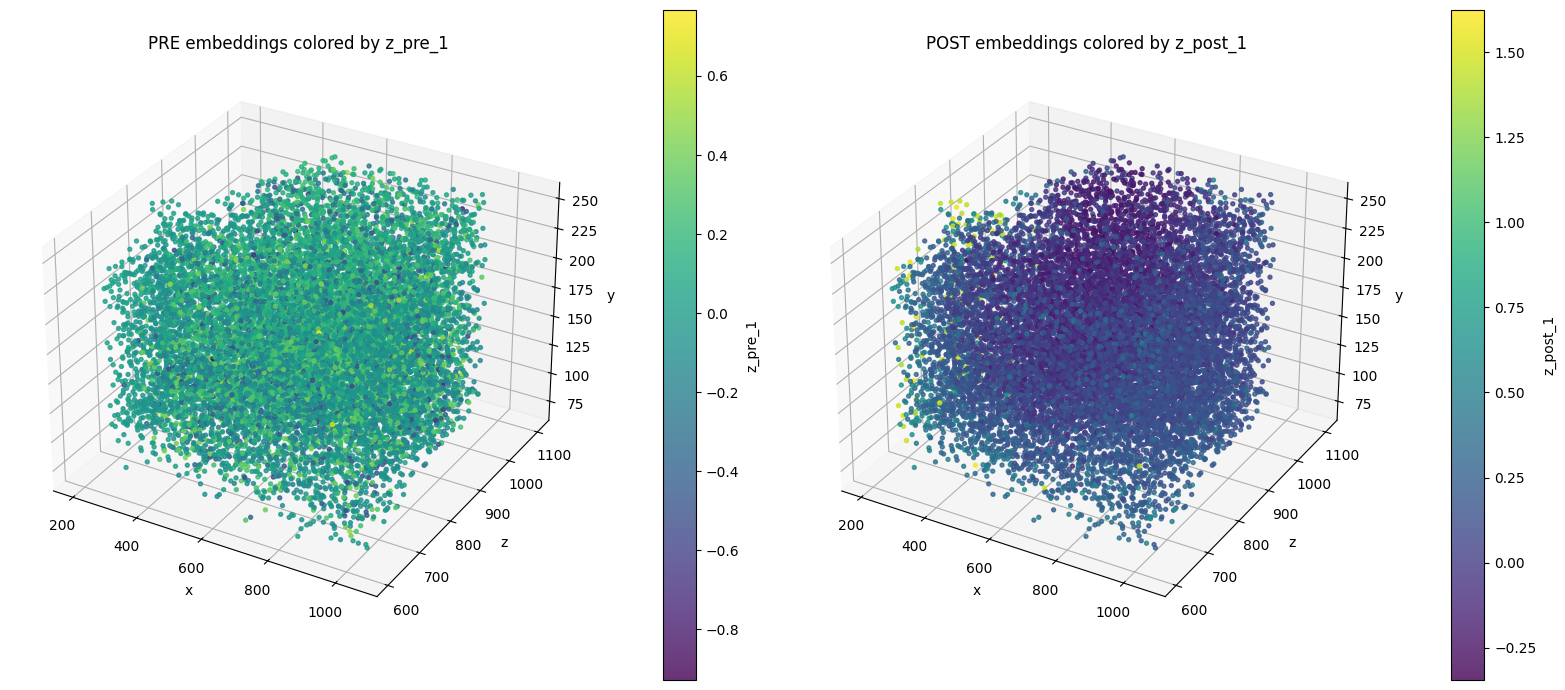

In [25]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# =========================
# PRE embeddings
# =========================

df_pre = df_Z_pre_full.dropna(
    subset=[
        "pt_position_x",
        "pt_position_y",
        "pt_position_z",
        "z_pre_1"
    ]
).copy()

# =========================
# POST embeddings
# =========================

df_post = df_Z_post_full.dropna(
    subset=[
        "pt_position_x",
        "pt_position_y",
        "pt_position_z",
        "z_post_1"
    ]
).copy()

# =========================
# Figure
# =========================

fig = plt.figure(figsize=(16, 7))

# =========================
# PRE subplot
# =========================

ax1 = fig.add_subplot(121, projection="3d")

sc1 = ax1.scatter(
    df_pre["pt_position_x"],
    df_pre["pt_position_z"],
    df_pre["pt_position_y"],   # y vertical
    c=df_pre["z_pre_1"],
    s=8,
    alpha=0.8,
    cmap="viridis"
)

ax1.set_xlabel("x")
ax1.set_ylabel("z")
ax1.set_zlabel("y")

ax1.set_title("PRE embeddings colored by z_pre_1")

cbar1 = plt.colorbar(
    sc1,
    ax=ax1,
    pad=0.1
)

cbar1.set_label("z_pre_1")

# =========================
# POST subplot
# =========================

ax2 = fig.add_subplot(122, projection="3d")

sc2 = ax2.scatter(
    df_post["pt_position_x"],
    df_post["pt_position_z"],
    df_post["pt_position_y"],   # y vertical
    c=df_post["z_post_1"],
    s=8,
    alpha=0.8,
    cmap="viridis"
)

ax2.set_xlabel("x")
ax2.set_ylabel("z")
ax2.set_zlabel("y")

ax2.set_title("POST embeddings colored by z_post_1")

cbar2 = plt.colorbar(
    sc2,
    ax=ax2,
    pad=0.1
)

cbar2.set_label("z_post_1")

plt.tight_layout()
plt.show()

C:\Users\Labour omnia vincit\AppData\Local\Temp\ipykernel_24388\3712020739.py:76: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


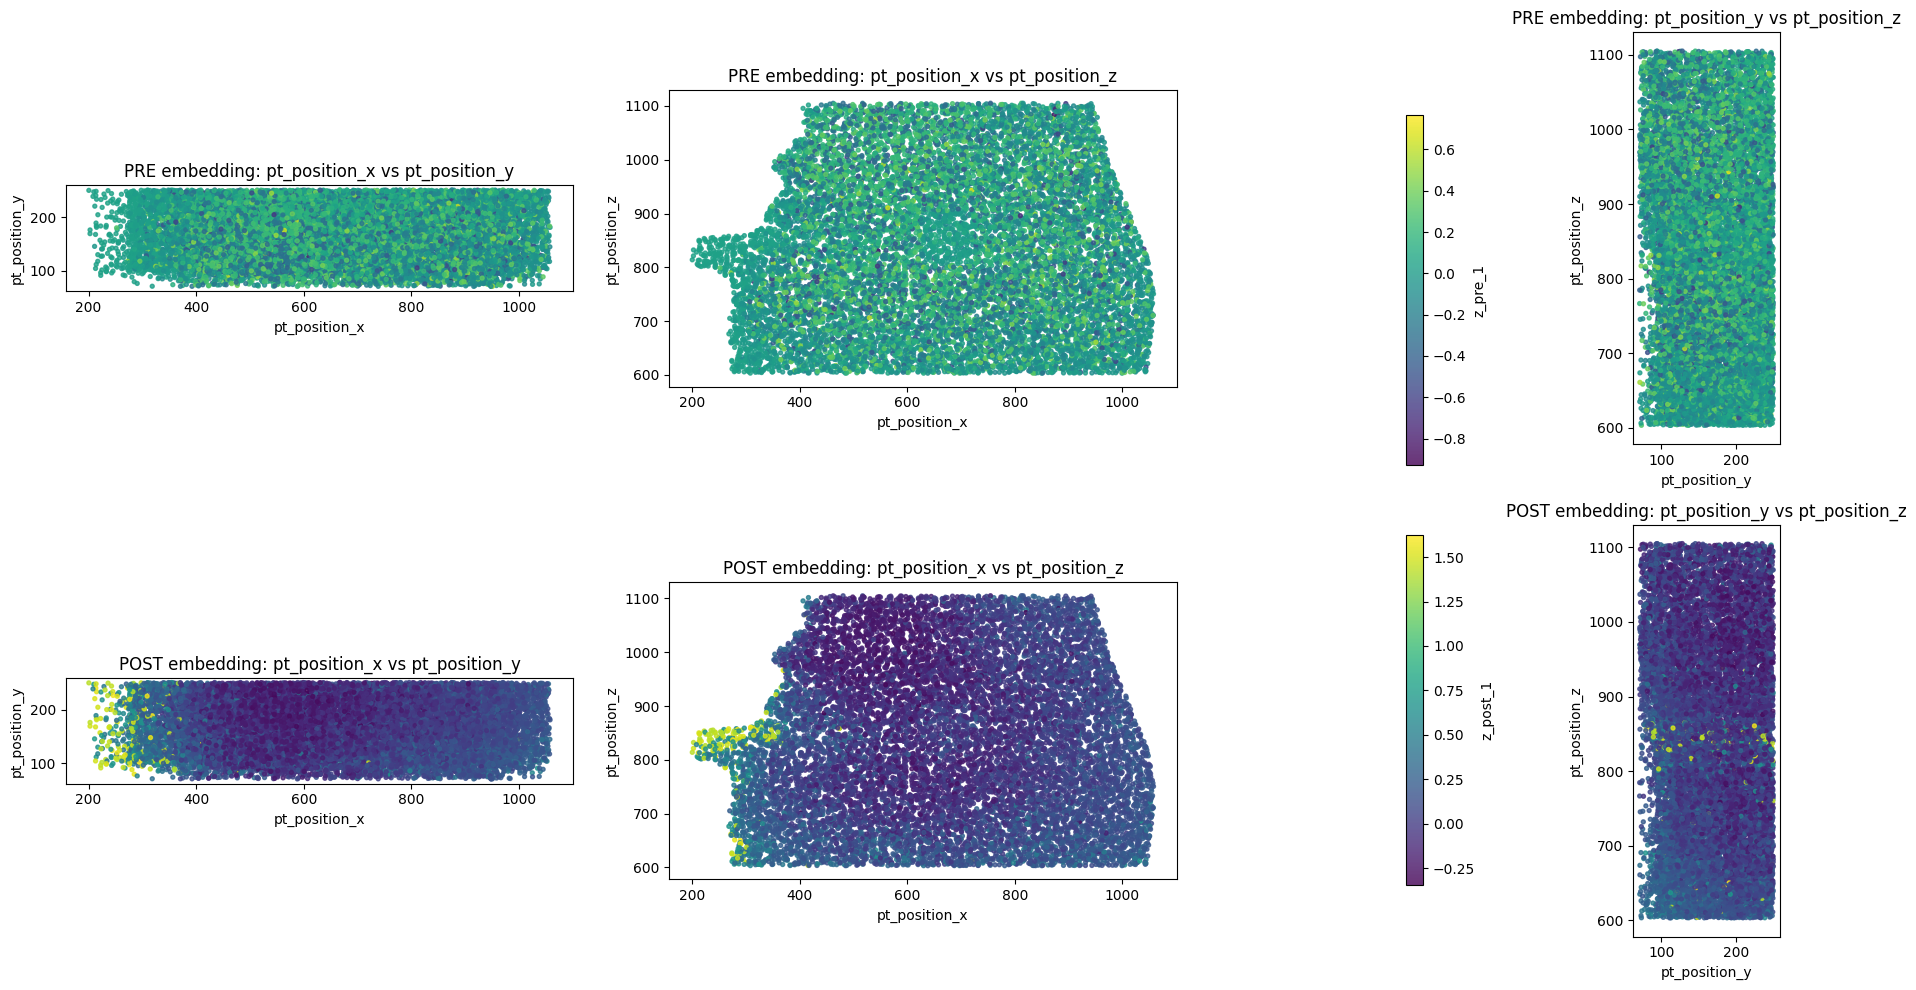

In [26]:
fig, axes = plt.subplots(
    2, 3,
    figsize=(18, 10)
)

pairs = [
    ("pt_position_x", "pt_position_y"),
    ("pt_position_x", "pt_position_z"),
    ("pt_position_y", "pt_position_z"),
]

# =========================
# PRE embeddings
# =========================

for ax, (a, b) in zip(axes[0], pairs):

    sc1 = ax.scatter(
        df_Z_pre_full[a],
        df_Z_pre_full[b],
        c=df_Z_pre_full["z_pre_1"],
        s=8,
        alpha=0.8,
        cmap="viridis"
    )

    ax.set_xlabel(a)
    ax.set_ylabel(b)

    ax.set_title(
        f"PRE embedding: {a} vs {b}"
    )

    ax.set_aspect("equal", adjustable="box")

# =========================
# POST embeddings
# =========================

for ax, (a, b) in zip(axes[1], pairs):

    sc2 = ax.scatter(
        df_Z_post_full[a],
        df_Z_post_full[b],
        c=df_Z_post_full["z_post_1"],
        s=8,
        alpha=0.8,
        cmap="viridis"
    )

    ax.set_xlabel(a)
    ax.set_ylabel(b)

    ax.set_title(
        f"POST embedding: {a} vs {b}"
    )

    ax.set_aspect("equal", adjustable="box")

# =========================
# Colorbars
# =========================

fig.colorbar(
    sc1,
    ax=axes[0],
    label="z_pre_1"
)

fig.colorbar(
    sc2,
    ax=axes[1],
    label="z_post_1"
)

plt.tight_layout()
plt.show()

In [27]:
# =========================
# PRE correlations
# =========================

print("=== PRE embeddings ===")

for coord in [
    "pt_position_x",
    "pt_position_y",
    "pt_position_z"
]:
    corr = df_Z_pre_full["z_pre_1"].corr(
        df_Z_pre_full[coord]
    )

    print(f"corr(z_pre_1, {coord}) = {corr:.3f}")

# =========================
# POST correlations
# =========================

print("\n=== POST embeddings ===")

for coord in [
    "pt_position_x",
    "pt_position_y",
    "pt_position_z"
]:
    corr = df_Z_post_full["z_post_1"].corr(
        df_Z_post_full[coord]
    )

    print(f"corr(z_post_1, {coord}) = {corr:.3f}")

=== PRE embeddings ===
corr(z_pre_1, pt_position_x) = -0.015
corr(z_pre_1, pt_position_y) = 0.050
corr(z_pre_1, pt_position_z) = 0.020

=== POST embeddings ===
corr(z_post_1, pt_position_x) = -0.161
corr(z_post_1, pt_position_y) = -0.176
corr(z_post_1, pt_position_z) = -0.305


In [28]:
# ============================================================
# Distance to center — PRE embeddings
# ============================================================

x0_pre = df_Z_pre_full["pt_position_x"].mean()
y0_pre = df_Z_pre_full["pt_position_y"].mean()
z0_pre = df_Z_pre_full["pt_position_z"].mean()

df_Z_pre_full["r_center"] = np.sqrt(
    (df_Z_pre_full["pt_position_x"] - x0_pre) ** 2 +
    (df_Z_pre_full["pt_position_y"] - y0_pre) ** 2 +
    (df_Z_pre_full["pt_position_z"] - z0_pre) ** 2
)

# ============================================================
# Distance to center — POST embeddings
# ============================================================

x0_post = df_Z_post_full["pt_position_x"].mean()
y0_post = df_Z_post_full["pt_position_y"].mean()
z0_post = df_Z_post_full["pt_position_z"].mean()

df_Z_post_full["r_center"] = np.sqrt(
    (df_Z_post_full["pt_position_x"] - x0_post) ** 2 +
    (df_Z_post_full["pt_position_y"] - y0_post) ** 2 +
    (df_Z_post_full["pt_position_z"] - z0_post) ** 2
)

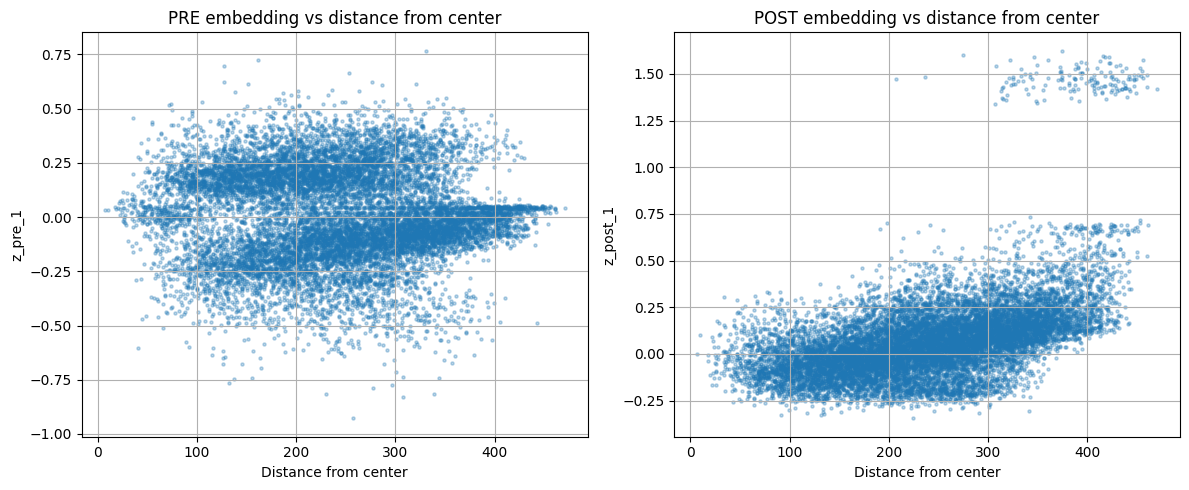

In [29]:
# ============================================================
# PRE: z_pre_1 vs distance from center
# ============================================================

fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 5)
)

# =========================
# PRE
# =========================

axes[0].scatter(
    df_Z_pre_full["r_center"],
    df_Z_pre_full["z_pre_1"],
    s=5,
    alpha=0.3
)

axes[0].set_xlabel("Distance from center")
axes[0].set_ylabel("z_pre_1")

axes[0].set_title(
    "PRE embedding vs distance from center"
)

axes[0].grid(True)

# =========================
# POST
# =========================

axes[1].scatter(
    df_Z_post_full["r_center"],
    df_Z_post_full["z_post_1"],
    s=5,
    alpha=0.3
)

axes[1].set_xlabel("Distance from center")
axes[1].set_ylabel("z_post_1")

axes[1].set_title(
    "POST embedding vs distance from center"
)

axes[1].grid(True)

plt.tight_layout()
plt.show()

In [30]:
# ============================================================
# Degree of neurons
# ============================================================

# =========================
# OUT degree
# =========================

out_degree = (
    synapses
    .groupby("pre_pt_root_id")
    .size()
    .rename("out_degree")
)

# =========================
# IN degree
# =========================

in_degree = (
    synapses
    .groupby("post_pt_root_id")
    .size()
    .rename("in_degree")
)

# ============================================================
# Merge with PRE embeddings
# ============================================================

df_Z_pre_full = df_Z_pre_full.merge(
    out_degree,
    left_on="pt_root_id",
    right_index=True,
    how="left"
)

df_Z_pre_full = df_Z_pre_full.merge(
    in_degree,
    left_on="pt_root_id",
    right_index=True,
    how="left"
)

df_Z_pre_full["out_degree"] = (
    df_Z_pre_full["out_degree"].fillna(0)
)

df_Z_pre_full["in_degree"] = (
    df_Z_pre_full["in_degree"].fillna(0)
)

# ============================================================
# Merge with POST embeddings
# ============================================================

df_Z_post_full = df_Z_post_full.merge(
    out_degree,
    left_on="pt_root_id",
    right_index=True,
    how="left"
)

df_Z_post_full = df_Z_post_full.merge(
    in_degree,
    left_on="pt_root_id",
    right_index=True,
    how="left"
)

df_Z_post_full["out_degree"] = (
    df_Z_post_full["out_degree"].fillna(0)
)

df_Z_post_full["in_degree"] = (
    df_Z_post_full["in_degree"].fillna(0)
)

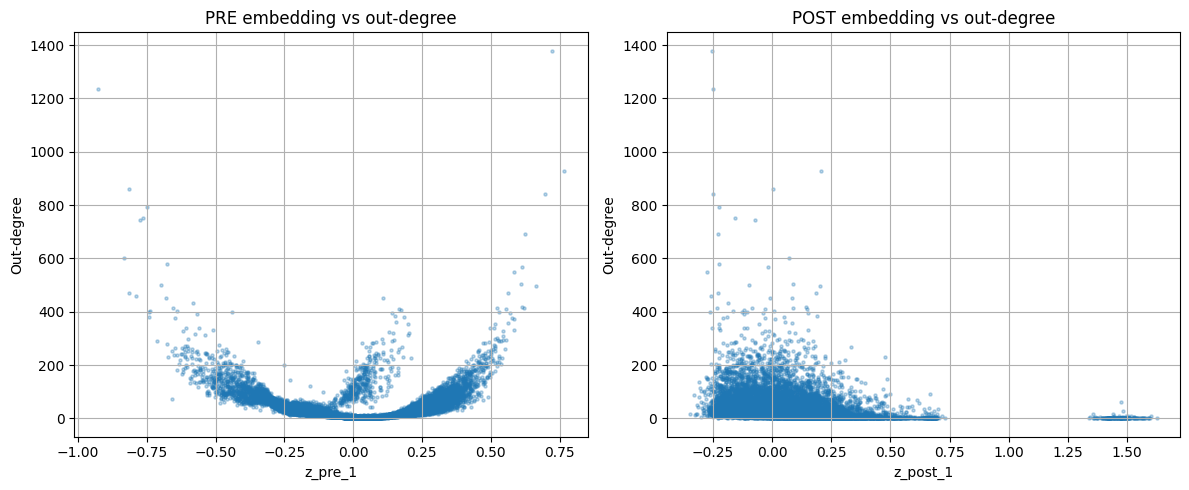

In [31]:
# ============================================================
# PRE embedding vs OUT degree
# ============================================================

fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 5)
)

# =========================
# PRE
# =========================

axes[0].scatter(
    df_Z_pre_full["z_pre_1"],
    df_Z_pre_full["out_degree"],
    s=5,
    alpha=0.3
)

axes[0].set_xlabel("z_pre_1")
axes[0].set_ylabel("Out-degree")

axes[0].set_title(
    "PRE embedding vs out-degree"
)

axes[0].grid(True)

# =========================
# POST
# =========================

axes[1].scatter(
    df_Z_post_full["z_post_1"],
    df_Z_post_full["out_degree"],
    s=5,
    alpha=0.3
)

axes[1].set_xlabel("z_post_1")
axes[1].set_ylabel("Out-degree")

axes[1].set_title(
    "POST embedding vs out-degree"
)

axes[1].grid(True)

plt.tight_layout()
plt.show()

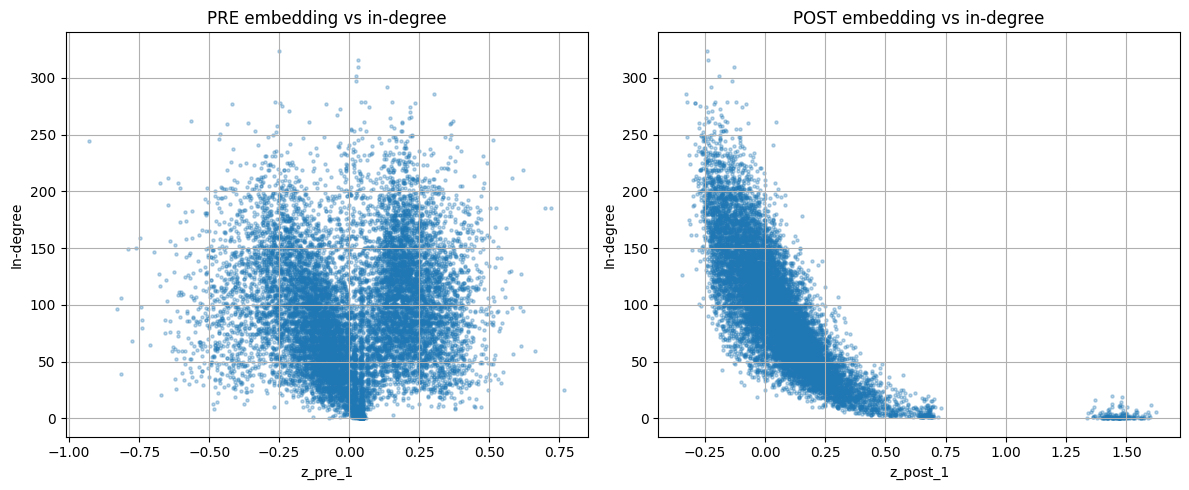

In [32]:
# ============================================================
# PRE embedding vs IN degree
# ============================================================

fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 5)
)

# =========================
# PRE
# =========================

axes[0].scatter(
    df_Z_pre_full["z_pre_1"],
    df_Z_pre_full["in_degree"],
    s=5,
    alpha=0.3
)

axes[0].set_xlabel("z_pre_1")
axes[0].set_ylabel("In-degree")

axes[0].set_title(
    "PRE embedding vs in-degree"
)

axes[0].grid(True)

# =========================
# POST
# =========================

axes[1].scatter(
    df_Z_post_full["z_post_1"],
    df_Z_post_full["in_degree"],
    s=5,
    alpha=0.3
)

axes[1].set_xlabel("z_post_1")
axes[1].set_ylabel("In-degree")

axes[1].set_title(
    "POST embedding vs in-degree"
)

axes[1].grid(True)

plt.tight_layout()
plt.show()

C:\Users\Labour omnia vincit\AppData\Local\Temp\ipykernel_24388\2983994125.py:59: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("bin")["connected"]


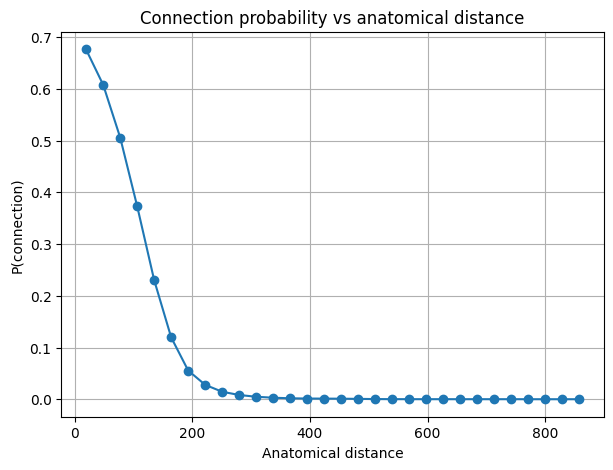

In [33]:
# ============================================================
# P(connection | anatomical distance)
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# Reconstruct anatomical positions
# ============================================================

id_to_pos = (
    units_cleaned
    .set_index("pt_root_id")[
        [
            "pt_position_x",
            "pt_position_y",
            "pt_position_z"
        ]
    ]
)

# Convert neuron indices -> pt_root_id
pre_ids = np.array(all_ids)[pre_idx.numpy()]
post_ids = np.array(all_ids)[post_idx.numpy()]

# Anatomical coordinates
pre_pos = id_to_pos.loc[pre_ids].values
post_pos = id_to_pos.loc[post_ids].values

# Euclidean distance
d_arr = np.sqrt(
    ((pre_pos - post_pos) ** 2).sum(axis=1)
)

# ============================================================
# DataFrame
# ============================================================

df_pairs = pd.DataFrame({
    "distance": d_arr,
    "connected": y.numpy()
})

# ============================================================
# Bin distances
# ============================================================

n_bins = 30

df_pairs["bin"] = pd.cut(
    df_pairs["distance"],
    bins=n_bins
)

prob_conn = (
    df_pairs
    .groupby("bin")["connected"]
    .mean()
)

bin_centers = np.array([
    interval.mid
    for interval in prob_conn.index
])

# ============================================================
# Plot
# ============================================================

plt.figure(figsize=(7, 5))

plt.plot(
    bin_centers,
    prob_conn.values,
    marker="o"
)

plt.xlabel("Anatomical distance")
plt.ylabel("P(connection)")
plt.title("Connection probability vs anatomical distance")

plt.grid(True)
plt.show()

In [34]:
# ============================================================
# Rebuild pair dataframe
# ============================================================

idx_to_id = np.array(all_ids)

pre_ids = idx_to_id[pre_idx.cpu().numpy()]
post_ids = idx_to_id[post_idx.cpu().numpy()]

df_pairs_full = pd.DataFrame({
    "pre_pt_root_id": pre_ids,
    "post_pt_root_id": post_ids,
    "connected": y.cpu().numpy(),
    "distance": d_arr
})

print(df_pairs_full.head())

       pre_pt_root_id     post_pt_root_id  connected    distance
0  864691135987557123  864691135275283429        0.0  161.280930
1  864691135841813731  864691135864909182        1.0  110.895004
2  864691135658905986  864691135585983612        0.0  221.910324
3  864691135491021287  864691135566123607        0.0  309.894287
4  864691135060075931  864691135976568131        0.0  376.645660


In [35]:
# ============================================================
# Rebuild pair dataframe
# ============================================================

idx_to_id = np.array(all_ids)

pre_ids = idx_to_id[pre_idx.numpy()]
post_ids = idx_to_id[post_idx.numpy()]

df_pairs_full = pd.DataFrame({
    "pre_pt_root_id": pre_ids,
    "post_pt_root_id": post_ids,
    "connected": y.numpy(),
    "distance": d_arr
})

print(df_pairs_full.head())
print(df_pairs_full.shape)

       pre_pt_root_id     post_pt_root_id  connected    distance
0  864691135987557123  864691135275283429        0.0  161.280930
1  864691135841813731  864691135864909182        1.0  110.895004
2  864691135658905986  864691135585983612        0.0  221.910324
3  864691135491021287  864691135566123607        0.0  309.894287
4  864691135060075931  864691135976568131        0.0  376.645660
(4644596, 4)


In [36]:
# ============================================================
# z_pre_1 and z_post_1 for each pair
# ============================================================

# PRE lookup
z_pre_lookup = dict(
    zip(
        df_Z_pre_full["pt_root_id"],
        df_Z_pre_full["z_pre_1"]
    )
)

# POST lookup
z_post_lookup = dict(
    zip(
        df_Z_post_full["pt_root_id"],
        df_Z_post_full["z_post_1"]
    )
)

# ============================================================
# Pair ids
# ============================================================

pre_ids = df_pairs_full["pre_pt_root_id"].values
post_ids = df_pairs_full["post_pt_root_id"].values

# ============================================================
# Retrieve latent values
# ============================================================

z_pre = np.array([
    z_pre_lookup[i]
    for i in pre_ids
])

z_post = np.array([
    z_post_lookup[i]
    for i in post_ids
])

# ============================================================
# Mean latent magnitude
# ============================================================

z_pair = (
    np.abs(z_pre) +
    np.abs(z_post)
) / 2

C:\Users\Labour omnia vincit\AppData\Local\Temp\ipykernel_24388\3583617020.py:38: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  p_conn = sub.groupby("bin")["connected"].mean()
C:\Users\Labour omnia vincit\AppData\Local\Temp\ipykernel_24388\3583617020.py:38: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  p_conn = sub.groupby("bin")["connected"].mean()
C:\Users\Labour omnia vincit\AppData\Local\Temp\ipykernel_24388\3583617020.py:38: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True 

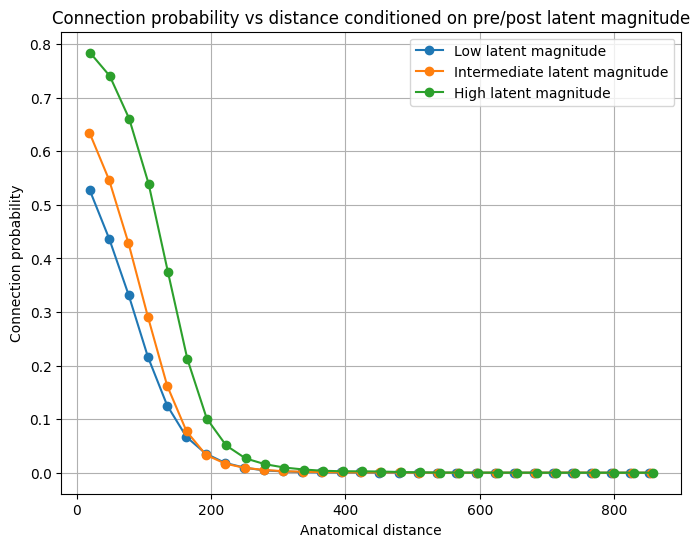

In [37]:
# ============================================================
# Split central / intermediate / peripheral according to z_pair
# ============================================================

q1 = np.quantile(z_pair, 0.33)
q2 = np.quantile(z_pair, 0.66)

labels = np.zeros(len(z_pair), dtype=int)
labels[z_pair > q1] = 1
labels[z_pair > q2] = 2

group_names = [
    "Low latent magnitude",
    "Intermediate latent magnitude",
    "High latent magnitude"
]

# ============================================================
# Connection probability vs distance conditioned on latent group
# ============================================================

plt.figure(figsize=(8, 6))

for g in range(3):

    mask = labels == g

    sub = pd.DataFrame({
        "distance": d_arr[mask],
        "connected": y.numpy()[mask]
    })

    sub["bin"] = pd.cut(
        sub["distance"],
        bins=n_bins
    )

    p_conn = sub.groupby("bin")["connected"].mean()

    centers = np.array([
        interval.mid for interval in p_conn.index
    ])

    plt.plot(
        centers,
        p_conn.values,
        marker="o",
        label=group_names[g]
    )

plt.xlabel("Anatomical distance")
plt.ylabel("Connection probability")
plt.title("Connection probability vs distance conditioned on pre/post latent magnitude")

plt.legend()
plt.grid(True)
plt.show()

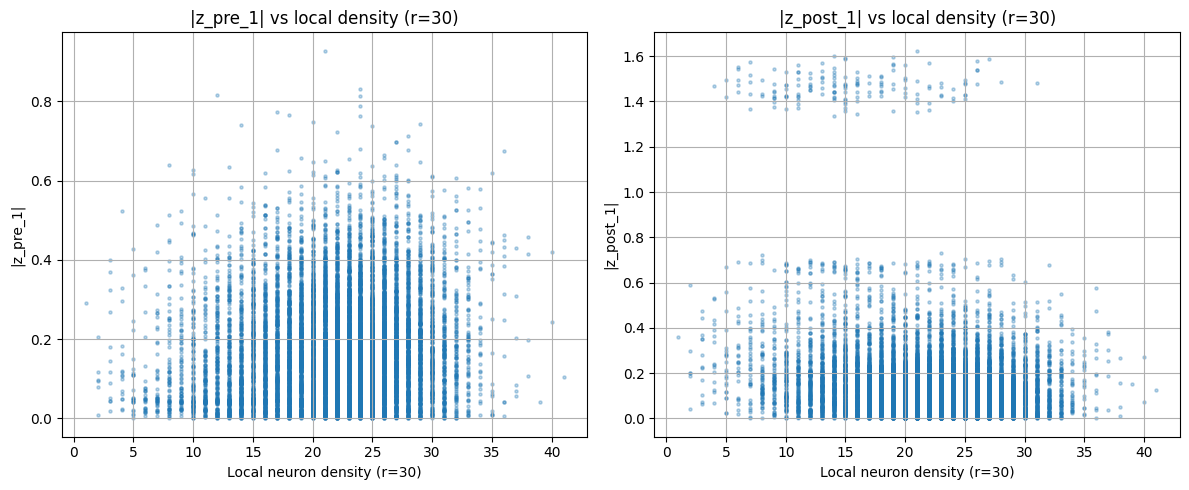

r=30 -> corr(|z_pre_1|, density)  = 0.116
r=30 -> corr(|z_post_1|, density) = -0.209


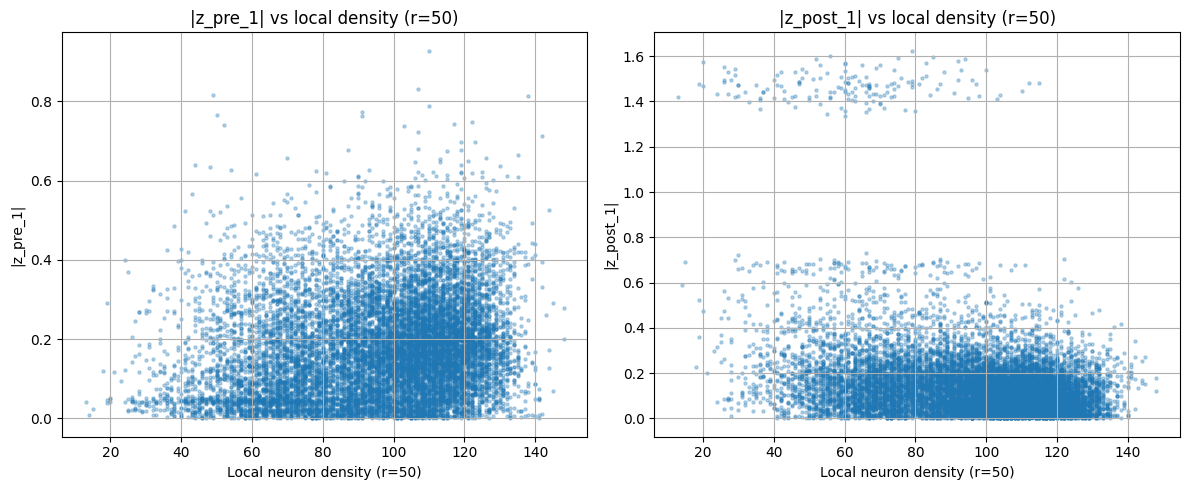

r=50 -> corr(|z_pre_1|, density)  = 0.183
r=50 -> corr(|z_post_1|, density) = -0.299


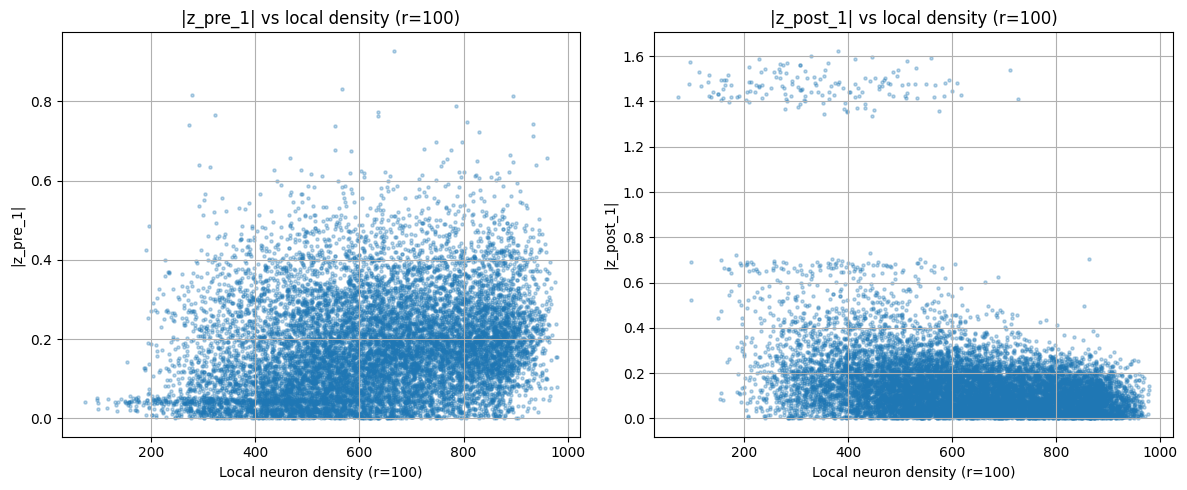

r=100 -> corr(|z_pre_1|, density)  = 0.230
r=100 -> corr(|z_post_1|, density) = -0.352


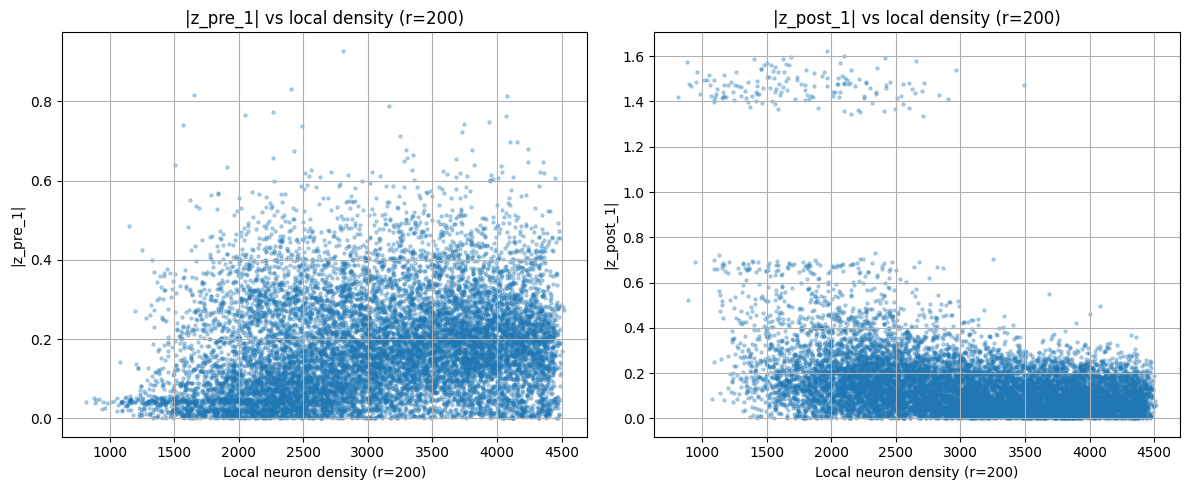

r=200 -> corr(|z_pre_1|, density)  = 0.215
r=200 -> corr(|z_post_1|, density) = -0.378


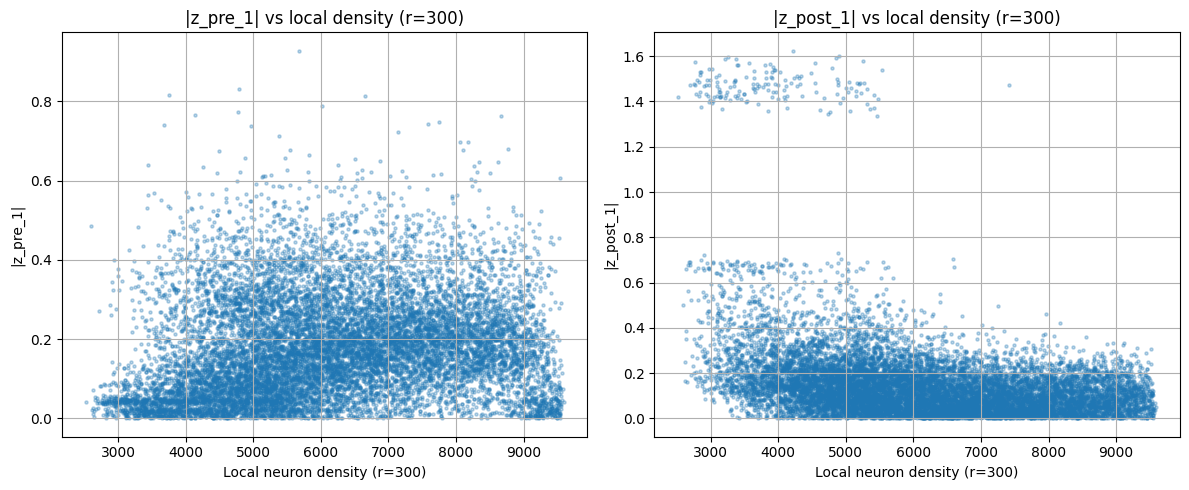

r=300 -> corr(|z_pre_1|, density)  = 0.177
r=300 -> corr(|z_post_1|, density) = -0.346


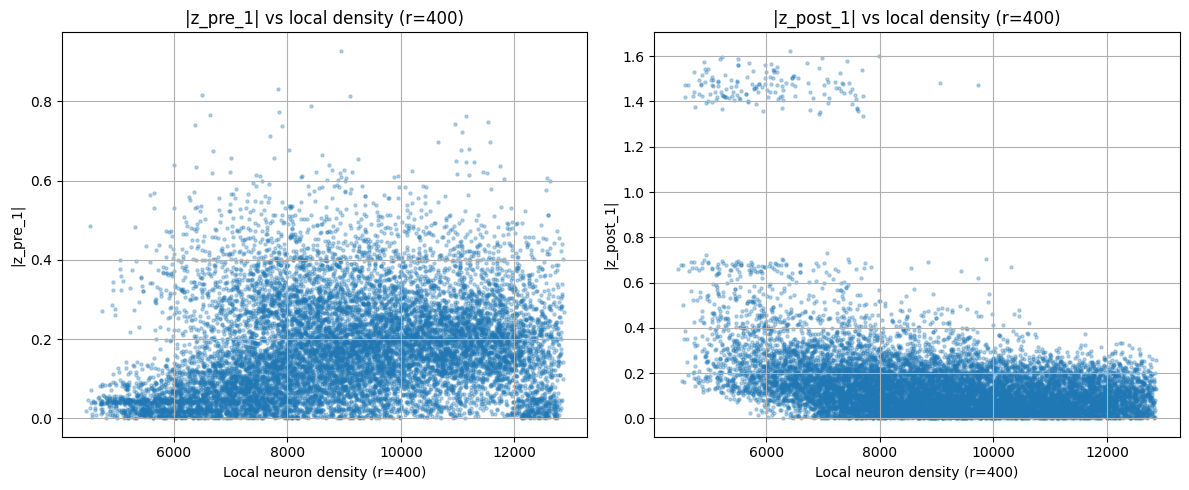

r=400 -> corr(|z_pre_1|, density)  = 0.205
r=400 -> corr(|z_post_1|, density) = -0.364


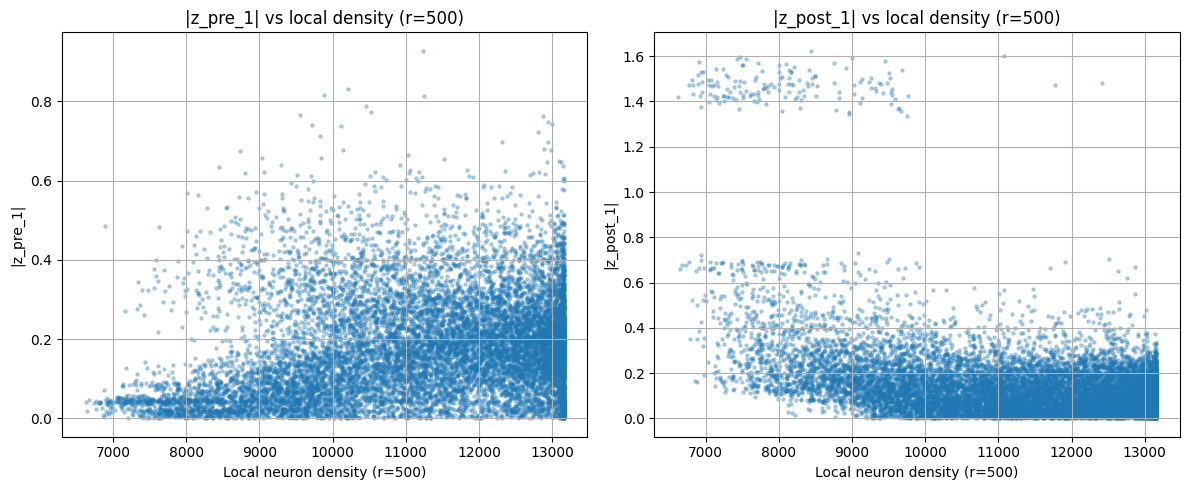

r=500 -> corr(|z_pre_1|, density)  = 0.239
r=500 -> corr(|z_post_1|, density) = -0.407


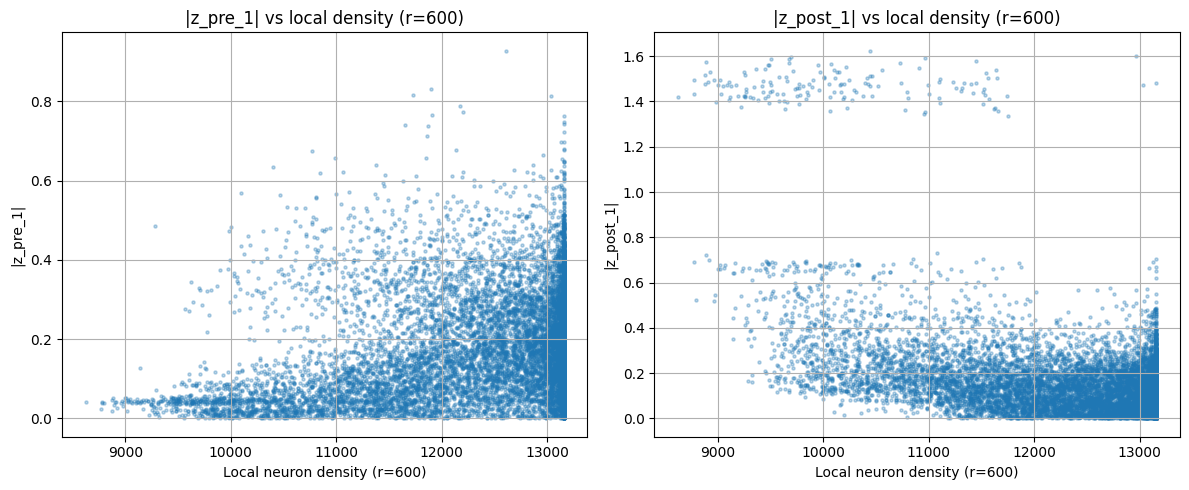

r=600 -> corr(|z_pre_1|, density)  = 0.267
r=600 -> corr(|z_post_1|, density) = -0.469


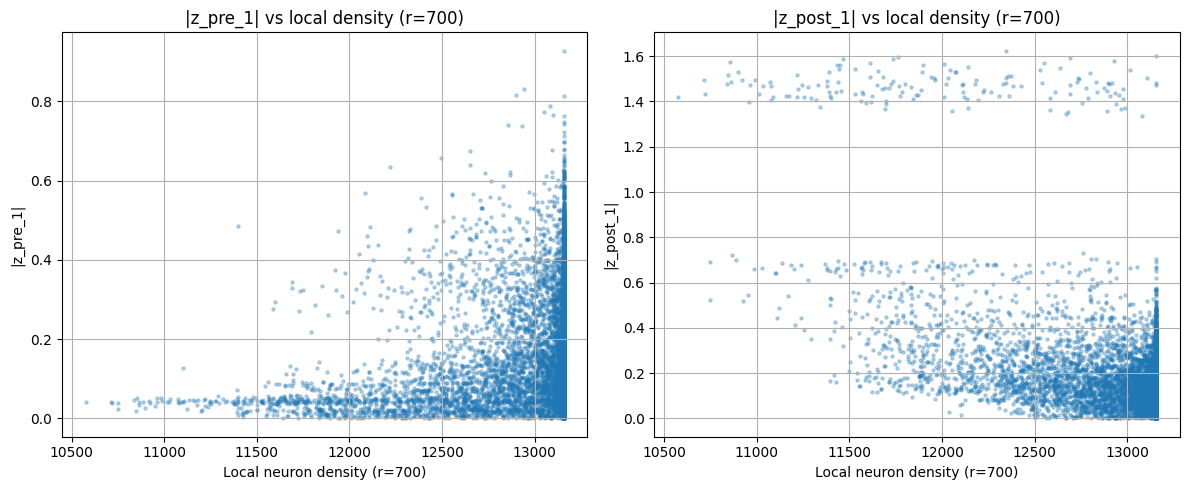

r=700 -> corr(|z_pre_1|, density)  = 0.263
r=700 -> corr(|z_post_1|, density) = -0.527


In [40]:
from scipy.spatial import cKDTree
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# Positions neuronales
# ============================================================

coords = df_Z_pre_full[[
    "pt_position_x",
    "pt_position_y",
    "pt_position_z"
]].values

tree = cKDTree(coords)

radii = [30, 50, 100, 200, 300, 400, 500, 600, 700]

for r in radii:

    neighbors = tree.query_ball_point(coords, r=r)

    density = np.array([
        len(n) - 1 for n in neighbors
    ])

    df_Z_pre_full[f"density_{r}"] = density
    df_Z_post_full[f"density_{r}"] = density

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    # PRE
    axes[0].scatter(
        density,
        np.abs(df_Z_pre_full["z_pre_1"]),
        s=5,
        alpha=0.3
    )

    axes[0].set_xlabel(f"Local neuron density (r={r})")
    axes[0].set_ylabel("|z_pre_1|")
    axes[0].set_title(f"|z_pre_1| vs local density (r={r})")
    axes[0].grid(True)

    corr_pre = np.corrcoef(
        density,
        np.abs(df_Z_pre_full["z_pre_1"])
    )[0, 1]

    # POST
    axes[1].scatter(
        density,
        np.abs(df_Z_post_full["z_post_1"]),
        s=5,
        alpha=0.3
    )

    axes[1].set_xlabel(f"Local neuron density (r={r})")
    axes[1].set_ylabel("|z_post_1|")
    axes[1].set_title(f"|z_post_1| vs local density (r={r})")
    axes[1].grid(True)

    corr_post = np.corrcoef(
        density,
        np.abs(df_Z_post_full["z_post_1"])
    )[0, 1]

    plt.tight_layout()
    plt.show()

    print(f"r={r} -> corr(|z_pre_1|, density)  = {corr_pre:.3f}")
    print(f"r={r} -> corr(|z_post_1|, density) = {corr_post:.3f}")

C:\Users\Labour omnia vincit\AppData\Local\Temp\ipykernel_30544\3539201793.py:54: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("bin")["connected"]


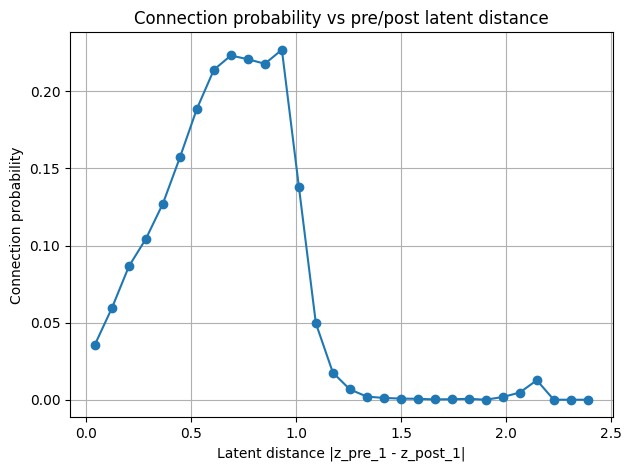

In [ ]:
# ============================================================
# P(connection | pre/post latent distance)
# ============================================================

# PRE lookup
z_pre_lookup = dict(
    zip(
        df_Z_pre_full["pt_root_id"],
        df_Z_pre_full["z_pre_1"]
    )
)

# POST lookup
z_post_lookup = dict(
    zip(
        df_Z_post_full["pt_root_id"],
        df_Z_post_full["z_post_1"]
    )
)

idx_to_id = np.array(all_ids)

pre_ids = idx_to_id[pre_idx.numpy()]
post_ids = idx_to_id[post_idx.numpy()]

z_pre_pair = np.array([
    z_pre_lookup[i]
    for i in pre_ids
])

z_post_pair = np.array([
    z_post_lookup[i]
    for i in post_ids
])

latent_distance = np.abs(
    z_pre_pair - z_post_pair
)

df_zdist = pd.DataFrame({
    "latent_distance": latent_distance,
    "connected": y.numpy()
})

n_bins = 30

df_zdist["bin"] = pd.cut(
    df_zdist["latent_distance"],
    bins=n_bins
)

p_conn_z = (
    df_zdist
    .groupby("bin")["connected"]
    .mean()
)

bin_centers_z = np.array([
    interval.mid
    for interval in p_conn_z.index
])

plt.figure(figsize=(7, 5))

plt.plot(
    bin_centers_z,
    p_conn_z.values,
    marker="o"
)

plt.xlabel("Latent distance |z_pre_1 - z_post_1|")
plt.ylabel("Connection probability")
plt.title("Connection probability vs pre/post latent distance")

plt.grid(True)
plt.show()

C:\Users\Labour omnia vincit\AppData\Local\Temp\ipykernel_30544\2524628391.py:19: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("bin")["connected"]
C:\Users\Labour omnia vincit\AppData\Local\Temp\ipykernel_30544\2524628391.py:78: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("bin")["connected"]


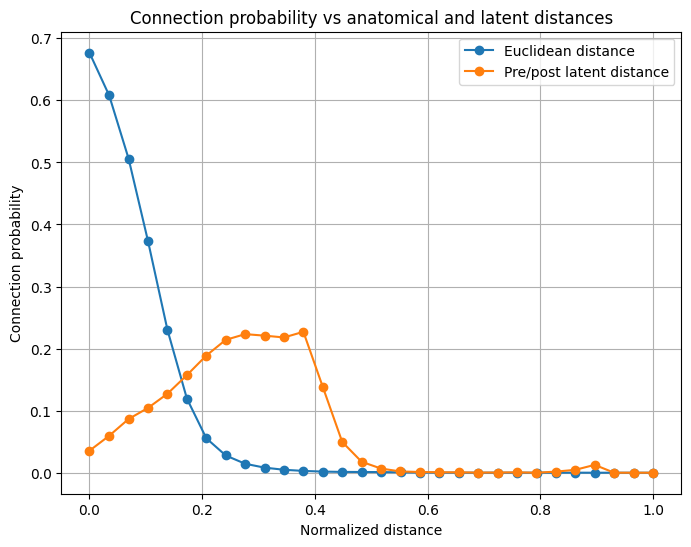

In [ ]:
# ============================================================
# P(connection | anatomical distance)
# ============================================================

df_euc = pd.DataFrame({
    "distance": d_arr,
    "connected": y.numpy()
})

n_bins = 30

df_euc["bin"] = pd.cut(
    df_euc["distance"],
    bins=n_bins
)

p_conn_euc = (
    df_euc
    .groupby("bin")["connected"]
    .mean()
)

centers_euc = np.array([
    interval.mid
    for interval in p_conn_euc.index
])


# ============================================================
# P(connection | pre/post latent distance)
# ============================================================

z_pre_lookup = dict(
    zip(
        df_Z_pre_full["pt_root_id"],
        df_Z_pre_full["z_pre_1"]
    )
)

z_post_lookup = dict(
    zip(
        df_Z_post_full["pt_root_id"],
        df_Z_post_full["z_post_1"]
    )
)

idx_to_id = np.array(all_ids)

pre_ids = idx_to_id[pre_idx.numpy()]
post_ids = idx_to_id[post_idx.numpy()]

z_pre_pair = np.array([
    z_pre_lookup[i]
    for i in pre_ids
])

z_post_pair = np.array([
    z_post_lookup[i]
    for i in post_ids
])

z_dist = np.abs(
    z_pre_pair - z_post_pair
)

df_z = pd.DataFrame({
    "z_dist": z_dist,
    "connected": y.numpy()
})

df_z["bin"] = pd.cut(
    df_z["z_dist"],
    bins=n_bins
)

p_conn_z = (
    df_z
    .groupby("bin")["connected"]
    .mean()
)

centers_z = np.array([
    interval.mid
    for interval in p_conn_z.index
])


# ============================================================
# Normalize x-axis for comparison
# ============================================================

x_euc = (
    centers_euc - centers_euc.min()
) / (
    centers_euc.max() - centers_euc.min()
)

x_z = (
    centers_z - centers_z.min()
) / (
    centers_z.max() - centers_z.min()
)


# ============================================================
# Plot
# ============================================================

plt.figure(figsize=(8, 6))

plt.plot(
    x_euc,
    p_conn_euc.values,
    marker="o",
    label="Euclidean distance"
)

plt.plot(
    x_z,
    p_conn_z.values,
    marker="o",
    label="Pre/post latent distance"
)

plt.xlabel("Normalized distance")
plt.ylabel("Connection probability")

plt.title(
    "Connection probability vs anatomical and latent distances"
)

plt.legend()
plt.grid(True)
plt.show()

radial_group
border          4474
center          4342
intermediate    4341
Name: count, dtype: int64
                   pair_type  n_pairs  n_pos  n_neg  positive_rate       auc
3              center-border    47852    593  47259       0.012392  0.874464
1              border-center    48232    521  47711       0.010802  0.868689
2        border-intermediate    50887   3320  47567       0.065243  0.844790
6        intermediate-border    50577   2985  47592       0.059019  0.838284
0              border-border    54851   6475  48376       0.118047  0.812733
5        center-intermediate    49839   4164  45675       0.083549  0.795862
8  intermediate-intermediate    53515   7558  45957       0.141231  0.794745
7        intermediate-center    49773   3621  46152       0.072750  0.790143
4              center-center    58935  12981  45954       0.220260  0.786558


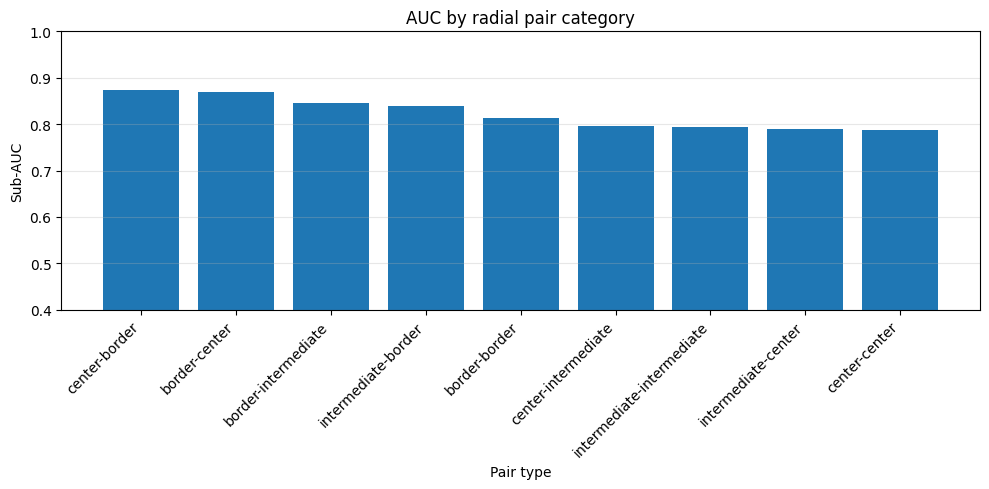

In [ ]:
from sklearn.metrics import roc_auc_score
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# Radial distance relative to Y axis
# r = sqrt((x-xc)^2 + (z-zc)^2)
# ============================================================

xc = df_Z_pre_full["pt_position_x"].mean()
zc = df_Z_pre_full["pt_position_z"].mean()

df_groups = df_Z_pre_full[[
    "pt_root_id",
    "pt_position_x",
    "pt_position_y",
    "pt_position_z"
]].copy()

df_groups["r_y_axis"] = np.sqrt(
    (df_groups["pt_position_x"] - xc) ** 2 +
    (df_groups["pt_position_z"] - zc) ** 2
)

# ============================================================
# Split neurons into 3 radial groups
# ============================================================

q1, q2 = df_groups["r_y_axis"].quantile([0.33, 0.66])

def radial_group(r):
    if r < q1:
        return "center"
    elif r < q2:
        return "intermediate"
    else:
        return "border"

df_groups["radial_group"] = df_groups["r_y_axis"].apply(radial_group)

print(df_groups["radial_group"].value_counts())

# ============================================================
# Build lookup table
# ============================================================

group_lookup = dict(
    zip(
        df_groups["pt_root_id"],
        df_groups["radial_group"]
    )
)

idx_to_id = np.array(all_ids)

pre_ids = idx_to_id[pre_idx.numpy()]
post_ids = idx_to_id[post_idx.numpy()]

# ============================================================
# Predicted probabilities from model
# ============================================================

model.eval()

all_probs = []

with torch.no_grad():
    for pi, pj, yb, pp, dp in test_loader:
        pi = pi.to(DEVICE, non_blocking=True)
        pj = pj.to(DEVICE, non_blocking=True)
        pp = pp.to(DEVICE, non_blocking=True)
        dp = dp.to(DEVICE, non_blocking=True)

        probs_batch = model(
            pi,
            pj,
            pp,
            dp
        ).detach().cpu().numpy()

        all_probs.append(probs_batch)

probs = np.concatenate(all_probs)

# ============================================================
# Rebuild test indices
# ============================================================

test_indices = np.array(test_set.indices)

pre_ids_test = pre_ids[test_indices]
post_ids_test = post_ids[test_indices]
labels_true = y.numpy()[test_indices]

# ============================================================
# Pair dataframe
# ============================================================

pair_df = pd.DataFrame({
    "pre_id": pre_ids_test,
    "post_id": post_ids_test,
    "y_true": labels_true,
    "y_pred": probs
})

pair_df["pre_group"] = [
    group_lookup[i] for i in pair_df["pre_id"]
]

pair_df["post_group"] = [
    group_lookup[i] for i in pair_df["post_id"]
]

pair_df["pair_type"] = (
    pair_df["pre_group"] +
    "-" +
    pair_df["post_group"]
)

# ============================================================
# Compute sub-AUCs
# ============================================================

results_auc = []

for pair_type, sub in pair_df.groupby("pair_type"):

    n_pos = sub["y_true"].sum()
    n_neg = len(sub) - n_pos

    if n_pos == 0 or n_neg == 0:
        continue

    auc = roc_auc_score(
        sub["y_true"],
        sub["y_pred"]
    )

    results_auc.append({
        "pair_type": pair_type,
        "n_pairs": len(sub),
        "n_pos": int(n_pos),
        "n_neg": int(n_neg),
        "positive_rate": sub["y_true"].mean(),
        "auc": auc
    })

results_auc = pd.DataFrame(results_auc)

results_auc = results_auc.sort_values(
    by="auc",
    ascending=False
)

print(results_auc)

# ============================================================
# Plot
# ============================================================

plt.figure(figsize=(10, 5))

plt.bar(
    results_auc["pair_type"],
    results_auc["auc"]
)

plt.ylabel("Sub-AUC")
plt.xlabel("Pair type")
plt.title("AUC by radial pair category")

plt.xticks(rotation=45, ha="right")
plt.ylim(0.4, 1.0)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

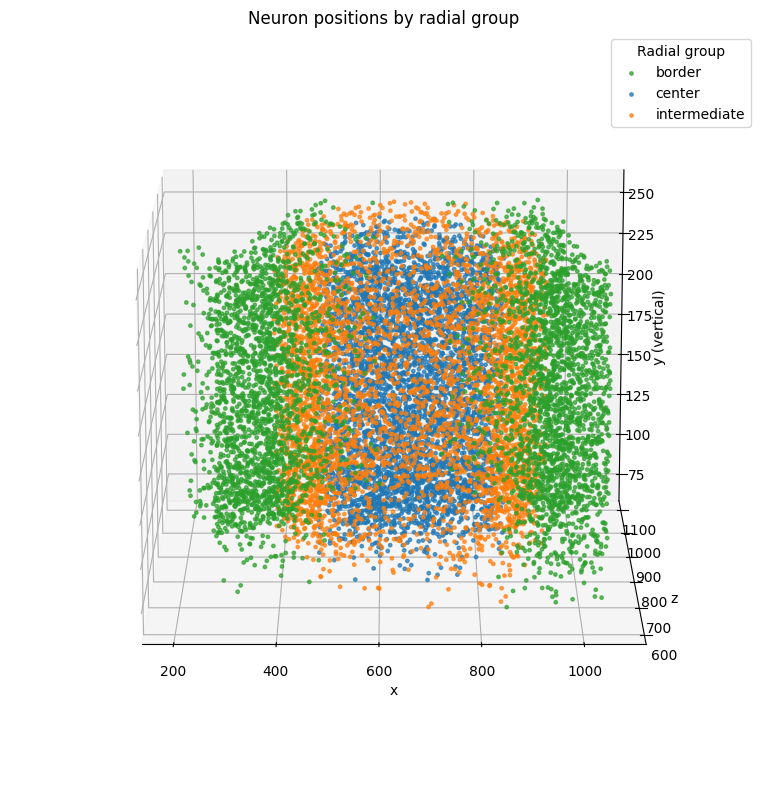

In [ ]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# ============================================================
# Color map
# ============================================================

color_map = {
    "center": "tab:blue",
    "intermediate": "tab:orange",
    "border": "tab:green",
}

# ============================================================
# Figure
# ============================================================

fig = plt.figure(figsize=(10, 8))

ax = fig.add_subplot(111, projection="3d")

# ============================================================
# Plot each radial group
# ============================================================

for group, sub in df_groups.groupby("radial_group"):

    ax.scatter(
        sub["pt_position_x"],   # x horizontal
        sub["pt_position_z"],   # z horizontal depth
        sub["pt_position_y"],   # y vertical
        s=6,
        alpha=0.7,
        label=group,
        color=color_map[group]
    )

# ============================================================
# Labels
# ============================================================

ax.set_xlabel("x")
ax.set_ylabel("z")
ax.set_zlabel("y (vertical)")

ax.set_title(
    "Neuron positions by radial group"
)

ax.legend(title="Radial group")

# ============================================================
# Camera angle
# ============================================================

ax.view_init(
    elev=15,
    azim=-90
)

plt.tight_layout()
plt.show()

post_group      center  intermediate    border
pre_group                                     
center        0.786558      0.795862  0.874464
intermediate  0.790143      0.794745  0.838284
border        0.868689      0.844790  0.812733


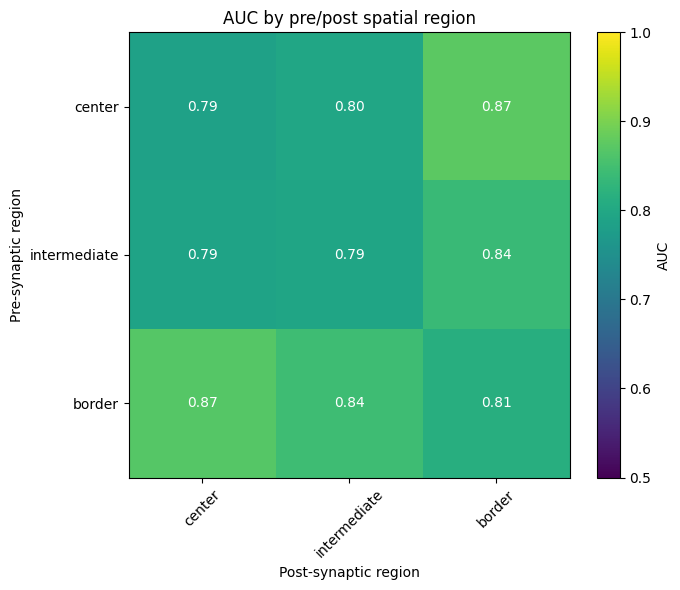

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
# ============================================================
# Split pair_type into pre/post groups
# ============================================================

results_auc[["pre_group", "post_group"]] = (
    results_auc["pair_type"]
    .str.split("-", expand=True)
)
# ============================================================
# Build AUC matrix
# ============================================================

auc_table = results_auc.pivot(
    index="pre_group",
    columns="post_group",
    values="auc"
)

# Optional: reorder rows/columns
order = ["center", "intermediate", "border"]

auc_table = auc_table.reindex(
    index=order,
    columns=order
)

print(auc_table)

plt.figure(figsize=(7, 6))

im = plt.imshow(
    auc_table,
    aspect="auto",
    cmap="viridis",
    vmin=0.5,
    vmax=1.0
)

cbar = plt.colorbar(im)
cbar.set_label("AUC")

# Axis labels
plt.xticks(
    ticks=np.arange(len(auc_table.columns)),
    labels=auc_table.columns,
    rotation=45
)

plt.yticks(
    ticks=np.arange(len(auc_table.index)),
    labels=auc_table.index
)

# Write AUC values inside cells
for i in range(len(auc_table.index)):
    for j in range(len(auc_table.columns)):

        value = auc_table.iloc[i, j]

        if not np.isnan(value):

            plt.text(
                j,
                i,
                f"{value:.2f}",
                ha="center",
                va="center",
                color="white",
                fontsize=10
            )

plt.xlabel("Post-synaptic region")
plt.ylabel("Pre-synaptic region")

plt.title(
    "AUC by pre/post spatial region"
)

plt.tight_layout()
plt.show()

C:\Users\Labour omnia vincit\AppData\Local\Temp\ipykernel_24388\1263481312.py:93: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("bin")


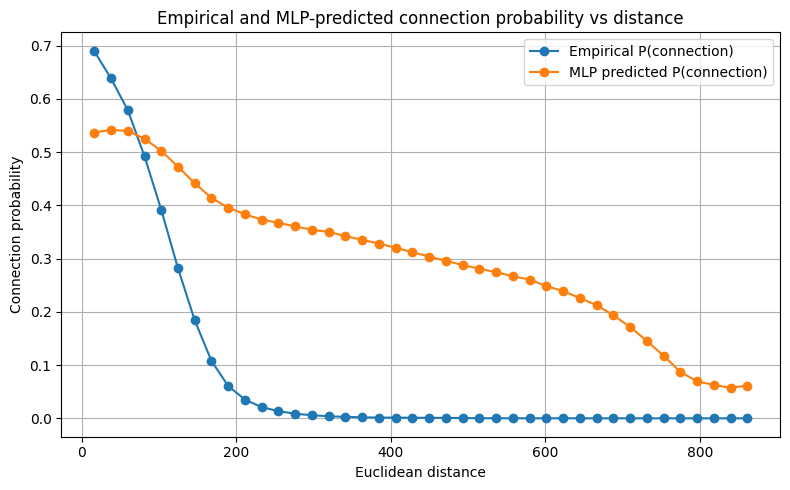

In [42]:
# ============================================================
# Empirical and MLP-predicted connection probability vs distance
# New model: Z_pre / Z_post + proofreading
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# Reconstruct pair ids
# ============================================================

idx_to_id = np.array(all_ids)

pre_ids = idx_to_id[pre_idx.numpy()]
post_ids = idx_to_id[post_idx.numpy()]

# ============================================================
# Get anatomical positions
# ============================================================

id_to_pos = (
    units_cleaned
    .set_index("pt_root_id")[
        ["pt_position_x", "pt_position_y", "pt_position_z"]
    ]
)

pre_pos = id_to_pos.loc[pre_ids].values
post_pos = id_to_pos.loc[post_ids].values

d_arr = np.sqrt(
    ((pre_pos - post_pos) ** 2).sum(axis=1)
)

# ============================================================
# Get model predictions in batches
# ============================================================

model.eval()

batch_size = 32768
all_probs = []

with torch.no_grad():

    for start in range(0, len(y), batch_size):

        end = start + batch_size

        pi = pre_idx[start:end].to(DEVICE)
        pj = post_idx[start:end].to(DEVICE)
        pp = pre_proof[start:end].to(DEVICE)
        dp = post_proof[start:end].to(DEVICE)

        probs_batch = model(
            pi,
            pj,
            pp,
            dp
        ).detach().cpu().numpy()

        all_probs.append(probs_batch)

probs_pred = np.concatenate(all_probs)

y_true = y.numpy()

# ============================================================
# Build dataframe
# ============================================================

df_curve = pd.DataFrame({
    "distance": d_arr,
    "y_true": y_true,
    "p_pred": probs_pred
})

# ============================================================
# Bin by Euclidean distance
# ============================================================

n_bins = 40

df_curve["bin"] = pd.cut(
    df_curve["distance"],
    bins=n_bins
)

curve = (
    df_curve
    .groupby("bin")
    .agg(
        empirical_prob=("y_true", "mean"),
        predicted_prob=("p_pred", "mean"),
        n_pairs=("y_true", "size"),
        n_connections=("y_true", "sum")
    )
)

bin_centers = np.array([
    interval.mid
    for interval in curve.index
])

# ============================================================
# Plot
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    bin_centers,
    curve["empirical_prob"],
    marker="o",
    label="Empirical P(connection)"
)

plt.plot(
    bin_centers,
    curve["predicted_prob"],
    marker="o",
    label="MLP predicted P(connection)"
)

plt.xlabel("Euclidean distance")
plt.ylabel("Connection probability")

plt.title(
    "Empirical and MLP-predicted connection probability vs distance"
)

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()